# Семинары 5–6: детекция и сегментация

- PASCAL VOC 2007: http://host.robots.ox.ac.uk/pascal/VOC/voc2007/
- `torchvision.ops` (`box_iou`, `nms`, `roi_align`, `sigmoid_focal_loss`): https://pytorch.org/vision/stable/ops.html
- `torchvision.transforms.v2` для боксов и масок: https://pytorch.org/vision/stable/transforms.html
- Ren et al., 2015 (Faster R-CNN: anchors, кодирование боксов): https://arxiv.org/abs/1506.01497
- Lin et al., 2017 (RetinaNet, focal loss): https://arxiv.org/abs/1708.02002
- Lin et al., 2017 (Feature Pyramid Network): https://arxiv.org/abs/1612.03144
- Ronneberger et al., 2015 (U-Net): https://arxiv.org/abs/1505.04597
- He et al., 2017 (Mask R-CNN, RoIAlign): https://arxiv.org/abs/1703.06870
- Дообучение детектора torchvision на своих данных: https://pytorch.org/tutorials/intermediate/torchvision_tutorial.html
- Penn-Fudan Pedestrian (Wang et al., 2007): https://www.cis.upenn.edu/~jshi/ped_html/
- Ultralytics YOLO: https://docs.ultralytics.com

**Перед семинаром** запустите ячейки до раздела 1 включительно: скачается PASCAL VOC 2007 (460 МБ). Веса всех моделей лежат в `checkpoints/`; при `TRAIN = False` ноутбук их загружает, а не учит: на MacBook Air M4 (MPS) детектор учится около часа, все модели вместе — около двух. Раздел 17 при первом запуске скачает Penn-Fudan (54 МБ) и веса Mask R-CNN (~180 МБ); для 17.3\* нужен `pip install ultralytics`.

## План

**Семинар 5. Детекция на PASCAL VOC**

1. Данные: PASCAL VOC 2007, разметка в XML
2. Боксы: форматы, файлы разметки, аугментации вместе с разметкой
3. IoU
4. Кодирование боксов: encode / decode
5. Anchors на пирамиде признаков и matching
6. Детектор: ResNet18 + FPN + головы, focal loss, обучение
7. NMS
8. \*GIoU

**Семинар 6. Оценка детектора и сегментация**

9. AP / mAP на VOC и разбор ошибок детектора
10. Семантическая сегментация VOC: маски, граница 255, попиксельный CE
11. Метрики: pixel accuracy, IoU / mIoU, Dice
12. U-Net с предобученным энкодером
13. Обучение U-Net, skip connections
14. Дисбаланс классов: Dice loss и focal loss
15. Instance segmentation: связные компоненты, бокс + маска, \*RoIAlign
16. FPN детектора как основа для сегментации
17. Fine-tune на своих данных: Mask R-CNN; 17.3\* YOLO

In [1]:
# !pip install torch torchvision matplotlib scipy
import math
import os
import shutil
import time
import xml.etree.ElementTree as ET

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
from scipy import ndimage

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import tv_tensors
from torchvision.datasets.utils import download_and_extract_archive
from torchvision.io import read_image
from torchvision.ops import (batched_nms, box_convert, box_iou, masks_to_boxes, nms,
                             roi_align, roi_pool, sigmoid_focal_loss)
from torchvision.transforms import v2

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.14.0
CUDA available:  False
MPS available:   True


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='mps')

In [3]:
FAST_MODE = True
TRAIN = False                 # False: веса из checkpoints/ (если файла нет — обучить); True: учить с нуля
CKPT_DIR = './checkpoints'
DATA_ROOT = './data'

DET_SIZE, SEG_SIZE = 320, 256   # фото приводим к квадрату: детектор — 320 x 320, сегментация — 256 x 256
BATCH_SIZE = 16
DET_EPOCHS = 20 if FAST_MODE else 40
SEG_EPOCHS = 40 if FAST_MODE else 80
LOSS_EPOCHS = 10 if FAST_MODE else 20   # короткий одинаковый бюджет для сравнения loss (раздел 14)
PENN_EPOCHS = 6 if FAST_MODE else 12    # дообучение голов Mask R-CNN (раздел 17)
YOLO_EPOCHS = 30 if FAST_MODE else 60   # дообучение YOLO (раздел 17.3*)
N_VAL_DET = 1000 if FAST_MODE else 2510  # сколько фото val для оценки детектора

---
# Семинар 5. Детекция на PASCAL VOC

# 1. Данные: PASCAL VOC 2007

Детекция: для каждого объекта на фото — класс и прямоугольник (**bounding box**), число объектов заранее неизвестно. PASCAL VOC 2007 — 20 классов, у каждого фото XML-файл разметки; часть фото размечена ещё и попиксельно (раздел 10). Архив 460 МБ скачивается при первом запуске.

In [4]:
VOC_ROOT = os.path.join(DATA_ROOT, 'VOCdevkit', 'VOC2007')
if not os.path.exists(VOC_ROOT):
    download_and_extract_archive('http://host.robots.ox.ac.uk/pascal/VOC/voc2007/VOCtrainval_06-Nov-2007.tar', DATA_ROOT)
sorted(os.listdir(VOC_ROOT))

['Annotations',
 'ImageSets',
 'JPEGImages',
 'SegmentationClass',
 'SegmentationObject']

In [5]:
CLASSES = ['aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow',
           'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']
K = len(CLASSES)


def read_ids(task, split):
    return open(os.path.join(VOC_ROOT, 'ImageSets', task, f'{split}.txt')).read().split()


det_ids = {split: read_ids('Main', split) for split in ['train', 'val']}
{split: len(ids) for split, ids in det_ids.items()}

{'train': 2501, 'val': 2510}

In [6]:
print(open(os.path.join(VOC_ROOT, 'Annotations', f"{det_ids['train'][0]}.xml")).read())

<annotation>
	<folder>VOC2007</folder>
	<filename>000012.jpg</filename>
	<source>
		<database>The VOC2007 Database</database>
		<annotation>PASCAL VOC2007</annotation>
		<image>flickr</image>
		<flickrid>207539885</flickrid>
	</source>
	<owner>
		<flickrid>KevBow</flickrid>
		<name>?</name>
	</owner>
	<size>
		<width>500</width>
		<height>333</height>
		<depth>3</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>car</name>
		<pose>Rear</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>156</xmin>
			<ymin>97</ymin>
			<xmax>351</xmax>
			<ymax>270</ymax>
		</bndbox>
	</object>
</annotation>



Пиксель $(i, j)$ — строка $i$, столбец $j$ — занимает квадрат $[j, j + 1) \times [i, i + 1)$; координаты боксов непрерывные, $x$ — вправо, $y$ — вниз. В XML VOC пиксели нумеруются с 1, правый край включается: $x_{\min} = 1$ — первый столбец. Поэтому $x_1 = x_{\min} - 1$, $x_2 = x_{\max}$, и тогда $w = x_2 - x_1$ — ровно ширина в пикселях. Флаг `difficult` — объект трудно распознать (мелкий, сильно закрыт); при оценке его не считают ни находкой, ни пропуском (раздел 9).

In [7]:
def parse_voc(image_id):
    root = ET.parse(os.path.join(VOC_ROOT, 'Annotations', f'{image_id}.xml')).getroot()
    objects = root.findall('object')
    boxes = torch.tensor([[float(o.find('bndbox').find(k).text) for k in ('xmin', 'ymin', 'xmax', 'ymax')]
                          for o in objects]).reshape(-1, 4)
    return dict(boxes=boxes - torch.tensor([1., 1., 0., 0.]),   # с 1 и включительно -> непрерывные координаты
                labels=torch.tensor([CLASSES.index(o.find('name').text) for o in objects]),
                difficult=torch.tensor([o.find('difficult').text == '1' for o in objects]),
                width=int(root.find('size').find('width').text), height=int(root.find('size').find('height').text))


parse_voc(det_ids['train'][0])

{'boxes': tensor([[155.,  96., 351., 270.]]),
 'labels': tensor([6]),
 'difficult': tensor([False]),
 'width': 500,
 'height': 333}

In [8]:
annotations = {i: parse_voc(i) for split in det_ids.values() for i in split}
train_labels = torch.cat([annotations[i]['labels'] for i in det_ids['train']])
n_objects = torch.tensor([len(annotations[i]['labels']) for i in det_ids['train']])
sizes = torch.tensor([[a['height'], a['width']] for a in annotations.values()])
print(f'train: {len(train_labels)} objects, {n_objects.float().mean():.2f} per image (max {n_objects.max()}), '
      f"difficult {torch.cat([annotations[i]['difficult'] for i in det_ids['train']]).float().mean():.3f}")
print(f'image size (H, W): from {sizes.min(dim=0).values.tolist()} to {sizes.max(dim=0).values.tolist()}')

train: 7844 objects, 3.14 per image (max 37), difficult 0.197
image size (H, W): from [96, 127] to [500, 500]


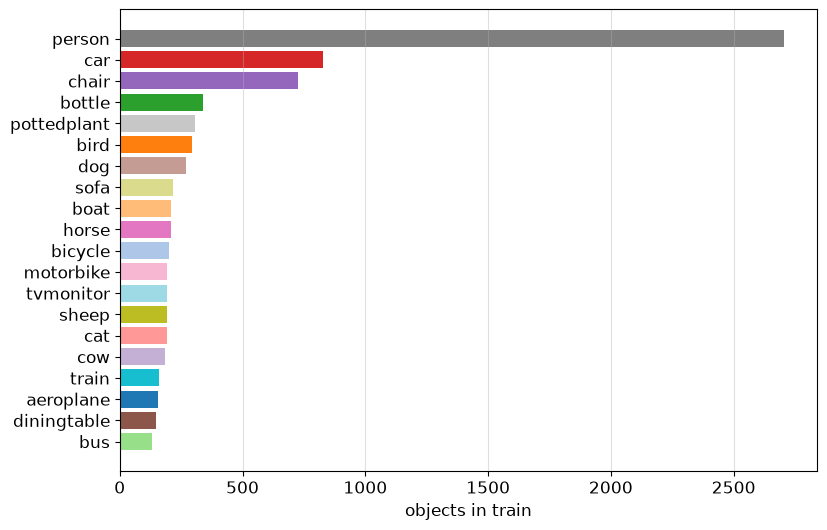

In [9]:
CLASS_COLORS = plt.cm.tab20.colors   # цвет класса c — на весь ноутбук: боксы и маски

class_counts = torch.bincount(train_labels, minlength=K)
order = class_counts.argsort()
plt.figure(figsize=(9, 6))
plt.barh([CLASSES[c] for c in order], class_counts[order], color=[CLASS_COLORS[c] for c in order])
plt.xlabel('objects in train')
plt.grid(True, axis='x', alpha=0.4)
plt.show()

Классы несбалансированы: `person` — больше трети из 7844 объектов train, у `bus` и `diningtable` — меньше 150. Частота — не главное для качества: в разделе 9 крупные `bus` и `train` детектор находит лучше, чем частые, но мелкие `bottle` и `chair`.

In [10]:
def show_detections(ax, image, boxes, labels, scores=None, text=True, linewidth=2):
    # image: (3, H, W), uint8 или float в [0, 1]
    image = image.float() / 255 if image.dtype == torch.uint8 else image
    ax.imshow(image.permute(1, 2, 0).cpu().clamp(0, 1))
    placed = []   # позиции подписей: соседние подписи сдвигаем вниз
    for k, (x1, y1, x2, y2) in enumerate(boxes.tolist()):
        color = CLASS_COLORS[labels[k]]
        # imshow рисует пиксель j на [j - 0.5, j + 0.5], у нас он на [j, j + 1)
        ax.add_patch(Rectangle((x1 - 0.5, y1 - 0.5), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=linewidth))
        if text:
            caption = CLASSES[labels[k]] + ('' if scores is None else f' {scores[k]:.2f}')
            y = y1
            while any(abs(x1 - px) < 40 and abs(y - py) < 12 for px, py in placed):
                y += 12
            placed.append((x1, y))
            ax.text(x1, y, caption, color='white', fontsize=8, va='top', bbox=dict(facecolor=color, pad=1, edgecolor='none'))
    ax.set_xticks([])
    ax.set_yticks([])

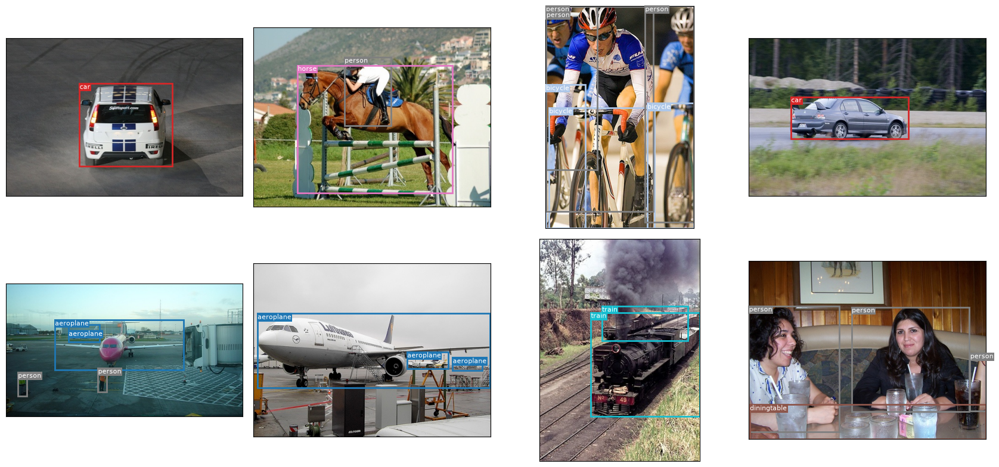

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, image_id in zip(axes.flat, det_ids['train'][:8]):
    ann = annotations[image_id]
    show_detections(ax, read_image(os.path.join(VOC_ROOT, 'JPEGImages', f'{image_id}.jpg')), ann['boxes'], ann['labels'])
plt.tight_layout()
plt.show()

---
# 2. Боксы: форматы, файлы разметки, аугментации

| формат бокса | координаты | где |
|---|---|---|
| `xyxy` | $(x_1, y_1, x_2, y_2)$ — углы | torchvision, Pascal VOC |
| `xywh` | $(x_1, y_1, w, h)$ | COCO |
| `cxcywh` | $(c_x, c_y, w, h)$ | YOLO, DETR, кодирование боксов (раздел 4) |

$$w = x_2 - x_1, \quad h = y_2 - y_1, \quad c_x = \tfrac{x_1 + x_2}{2}, \quad c_y = \tfrac{y_1 + y_2}{2}.$$

In [12]:
def xyxy_to_cxcywh(b):
    x1, y1, x2, y2 = b.unbind(-1)
    return torch.stack([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1], dim=-1)


def cxcywh_to_xyxy(b):
    cx, cy, w, h = b.unbind(-1)
    return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], dim=-1)


boxes = annotations[det_ids['train'][1]]['boxes']
assert torch.allclose(xyxy_to_cxcywh(boxes), box_convert(boxes, 'xyxy', 'cxcywh'))
assert torch.allclose(cxcywh_to_xyxy(xyxy_to_cxcywh(boxes)), boxes)
boxes, box_convert(boxes, 'xyxy', 'xywh')   # COCO: левый верхний угол и размер

(tensor([[184.,  61., 279., 199.],
         [ 89.,  77., 403., 336.]]),
 tensor([[184.,  61.,  95., 138.],
         [ 89.,  77., 314., 259.]]))

### Файлы разметки

| формат | бокс | хранение |
|---|---|---|
| Pascal VOC | `xyxy` в пикселях, с 1 и включительно | XML на картинку |
| COCO | `xywh` в пикселях | один JSON на датасет: `images`, `annotations`, `categories` |
| YOLO | класс + `cxcywh`, нормированные на размер картинки | TXT на картинку, строка на объект |

Инструменты разметки (CVAT, Label Studio) экспортируют в любой из них; конвертация — несколько строк.

In [13]:
def to_coco(image_ids):
    images, objects = [], []
    for n, image_id in enumerate(image_ids):
        ann = annotations[image_id]
        images.append(dict(id=n, file_name=f'{image_id}.jpg', width=ann['width'], height=ann['height']))
        for box, label in zip(box_convert(ann['boxes'], 'xyxy', 'xywh').tolist(), ann['labels'].tolist()):
            objects.append(dict(id=len(objects), image_id=n, category_id=label, bbox=box, area=box[2] * box[3], iscrowd=0))
    return dict(images=images, annotations=objects, categories=[dict(id=c, name=name) for c, name in enumerate(CLASSES)])


coco = to_coco(det_ids['train'])
len(coco['images']), len(coco['annotations']), coco['annotations'][0]

(2501,
 7844,
 {'id': 0,
  'image_id': 0,
  'category_id': 6,
  'bbox': [155.0, 96.0, 196.0, 174.0],
  'area': 34104.0,
  'iscrowd': 0})

In [14]:
def to_yolo(ann):
    size = torch.tensor([ann['width'], ann['height']] * 2)
    rows = box_convert(ann['boxes'], 'xyxy', 'cxcywh') / size   # нормировка на размер картинки
    return '\n'.join(f'{c} ' + ' '.join(f'{v:.6f}' for v in row) for c, row in zip(ann['labels'].tolist(), rows.tolist()))


def from_yolo(text, width, height):
    rows = torch.tensor([[float(v) for v in line.split()] for line in text.splitlines()])
    return box_convert(rows[:, 1:] * torch.tensor([width, height] * 2), 'cxcywh', 'xyxy'), rows[:, 0].long()


ann = annotations[det_ids['train'][1]]
boxes_back, labels_back = from_yolo(to_yolo(ann), ann['width'], ann['height'])
assert torch.allclose(boxes_back, ann['boxes'], atol=1e-2) and torch.equal(labels_back, ann['labels'])
print(to_yolo(ann))

14 0.482292 0.357143 0.197917 0.379121
12 0.512500 0.567308 0.654167 0.711538


## 2.1 Аугментации вместе с разметкой

Отразили картинку — боксы должны отразиться тоже. `torchvision.transforms.v2` понимает типы `tv_tensors.BoundingBoxes` и `tv_tensors.Mask` и применяет к ним то же преобразование, что к картинке; прочие поля target (метки, флаги) проходят без изменений.

In [15]:
class VOCDetection(Dataset):
    # (image, target): target — dict с boxes (n, 4) в xyxy, labels (n,), difficult (n,)
    def __init__(self, image_ids, transforms):
        self.image_ids, self.transforms = image_ids, transforms

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, i):
        image_id = self.image_ids[i]
        image = tv_tensors.Image(read_image(os.path.join(VOC_ROOT, 'JPEGImages', f'{image_id}.jpg')))
        ann = annotations[image_id]
        target = dict(boxes=tv_tensors.BoundingBoxes(ann['boxes'], format='XYXY', canvas_size=image.shape[-2:]),
                      labels=ann['labels'], difficult=ann['difficult'])
        return self.transforms(image, target)

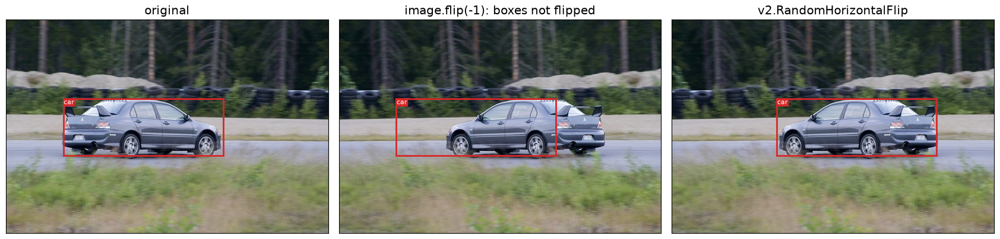

In [16]:
raw = VOCDetection(det_ids['train'], v2.Identity())
image, target = raw[3]
flip_image, flip_target = v2.RandomHorizontalFlip(p=1.0)(image, target)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
show_detections(axes[0], image, target['boxes'], target['labels'])
show_detections(axes[1], image.flip(-1), target['boxes'], target['labels'])
show_detections(axes[2], flip_image, flip_target['boxes'], flip_target['labels'])
for ax, title in zip(axes, ['original', 'image.flip(-1): boxes not flipped', 'v2.RandomHorizontalFlip']):
    ax.set_title(title)
plt.tight_layout()
plt.show()

Все фото приводим к $320 \times 320$ без сохранения пропорций (как в SSD): так их можно сложить в батч, а боксы масштабируются вместе с картинкой. IoU (раздел 3) от этого не меняется: растяжение по осям умножает площади всех боксов и их пересечений на одно и то же число.

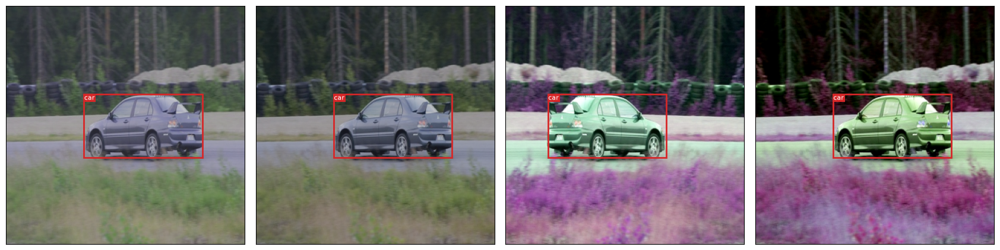

(torch.Size([3, 320, 320]),
 torch.float32,
 BoundingBoxes([[104.3200, 119.1592, 263.0400, 203.7237]], format=BoundingBoxFormat.XYXY, canvas_size=(320, 320), clamping_mode=soft))

In [17]:
det_test_tf = v2.Compose([v2.Resize((DET_SIZE, DET_SIZE)), v2.ToDtype(torch.float32, scale=True)])   # ToDtype — только картинка
det_train_tf = v2.Compose([v2.RandomHorizontalFlip(0.5), v2.RandomPhotometricDistort(p=0.5), det_test_tf])

det_train_set = VOCDetection(det_ids['train'], det_train_tf)
det_val_set = VOCDetection(det_ids['val'], det_test_tf)

torch.manual_seed(0)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
for ax in axes:
    image, target = det_train_set[3]
    show_detections(ax, image, target['boxes'], target['labels'])
plt.tight_layout()
plt.show()
image.shape, image.dtype, target['boxes']

---
# 3. IoU

$$\mathrm{IoU}(A, B) = \frac{|A \cap B|}{|A \cup B|} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|} \in [0, 1].$$

Пересечение двух боксов — тоже бокс (или пустое множество):
$$x_1^{\cap} = \max(x_1^A, x_1^B), \quad x_2^{\cap} = \min(x_2^A, x_2^B), \quad w^{\cap} = \max(0,\; x_2^{\cap} - x_1^{\cap}),$$
аналогично по $y$.

![IoU](figures/iou.svg)

In [18]:
def box_area(b):
    return (b[..., 2] - b[..., 0]) * (b[..., 3] - b[..., 1])


def pairwise_iou(a, b):
    # a: (N, 4), b: (M, 4) в xyxy -> (N, M)
    lt = torch.maximum(a[:, None, :2], b[None, :, :2])   # левый верхний угол пересечения
    rb = torch.minimum(a[:, None, 2:], b[None, :, 2:])   # правый нижний
    inter = (rb - lt).clamp(min=0).prod(dim=-1)
    return inter / (box_area(a)[:, None] + box_area(b)[None, :] - inter)

In [19]:
a = torch.tensor([[10., 10., 50., 50.]])
b = torch.tensor([[30., 30., 70., 70.],   # пересечение 20 x 20 = 400, объединение 1600 + 1600 - 400
                  [10., 10., 50., 50.],   # тот же бокс
                  [60., 0., 90., 30.]])   # не пересекаются
pairwise_iou(a, b)

tensor([[0.1429, 1.0000, 0.0000]])

In [20]:
torch.manual_seed(0)
xy = torch.rand(50, 2) * 300
random_boxes = torch.cat([xy, xy + 4 + torch.rand(50, 2) * 100], dim=1)
assert torch.allclose(pairwise_iou(random_boxes, boxes), box_iou(random_boxes, boxes))
pairwise_iou(random_boxes, boxes).shape

torch.Size([50, 2])

IoU — относительная мера: сдвиг на те же $\delta$ пикселей сильнее бьёт по маленькому боксу. Квадрат со стороной $s$, сдвинутый по диагонали на $\delta$:
$$\mathrm{IoU} = \frac{(s - \delta)^2}{2 s^2 - (s - \delta)^2}.$$

In [21]:
shifts = torch.arange(0, 13.)
iou_by_size = {}
for s in [16, 32, 64]:
    box = torch.tensor([[0., 0., s, s]])
    iou_by_size[s] = box_iou(box, box + shifts[:, None])[0]   # сдвиг по диагонали на delta
{s: round(v[4].item(), 3) for s, v in iou_by_size.items()}   # delta = 4 px

{16: 0.391, 32: 0.62, 64: 0.784}

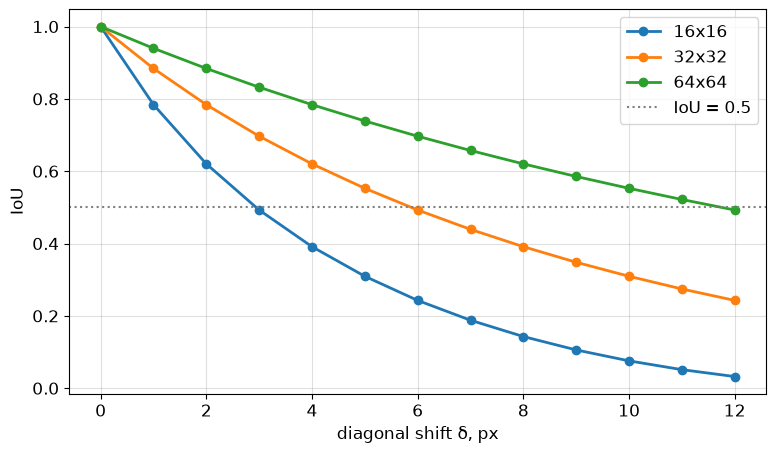

In [22]:
plt.figure(figsize=(9, 5))
for s, ious in iou_by_size.items():
    plt.plot(shifts, ious, 'o-', linewidth=2, label=f'{s}x{s}')
plt.axhline(0.5, color='gray', linestyle=':', label='IoU = 0.5')
plt.xlabel('diagonal shift δ, px')
plt.ylabel('IoU')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Сдвиг на 4 пикселя по диагонали оставляет квадрату $64 \times 64$ IoU 0.78, а квадрату $16 \times 16$ — 0.39, ниже порога 0.5. Маленькие объекты локализовать труднее, и метрики с порогом по IoU (раздел 9) это чувствуют.

---
# 4. Кодирование боксов

Сеть предсказывает не координаты бокса, а **поправку** к опорному боксу (anchor, раздел 5). Для anchor $a$ с центром $(x_a, y_a)$ и размером $w_a \times h_a$ и бокса $b$ с центром $(x, y)$ и размером $w \times h$ (Faster R-CNN):
$$t_x = \frac{x - x_a}{w_a}, \qquad t_y = \frac{y - y_a}{h_a}, \qquad t_w = \log\frac{w}{w_a}, \qquad t_h = \log\frac{h}{h_a};$$
$$x = x_a + t_x w_a, \qquad y = y_a + t_y h_a, \qquad w = w_a e^{t_w}, \qquad h = h_a e^{t_h}.$$

Сдвиг нормирован на размер anchor — одинаковая относительная ошибка у маленького и большого бокса даёт одинаковые $t$; $\log$ делает размер после decode положительным при любом выходе сети.

![box encoding](figures/box_encoding.svg)

In [23]:
def encode(boxes, anchors):
    # boxes, anchors: (N, 4) в xyxy -> t: (N, 4)
    x, y, w, h = box_convert(boxes, 'xyxy', 'cxcywh').unbind(-1)
    xa, ya, wa, ha = box_convert(anchors, 'xyxy', 'cxcywh').unbind(-1)
    return torch.stack([(x - xa) / wa, (y - ya) / ha, torch.log(w / wa), torch.log(h / ha)], dim=-1)


def decode(t, anchors, max_log_scale=math.log(1000 / 16)):
    xa, ya, wa, ha = box_convert(anchors, 'xyxy', 'cxcywh').unbind(-1)
    tx, ty, tw, th = t.unbind(-1)
    tw, th = tw.clamp(max=max_log_scale), th.clamp(max=max_log_scale)   # exp не переполнится на мусорном выходе
    cxcywh = torch.stack([xa + tx * wa, ya + ty * ha, wa * tw.exp(), ha * th.exp()], dim=-1)
    return box_convert(cxcywh, 'cxcywh', 'xyxy')

In [24]:
from torchvision.models.detection._utils import BoxCoder   # внутренний модуль: им пользуются детекторы torchvision

anchors_demo = random_boxes.flip(0)   # любые боксы в роли anchors
t = encode(random_boxes, anchors_demo)
assert torch.allclose(decode(t, anchors_demo), random_boxes, atol=1e-3)
coder = BoxCoder(weights=(1.0, 1.0, 1.0, 1.0))
assert torch.allclose(coder.encode_single(random_boxes, anchors_demo), t, atol=1e-5)
assert torch.allclose(coder.decode_single(t, anchors_demo), random_boxes, atol=1e-3)
t[:3]

tensor([[ 6.3751,  3.4820,  1.4290,  0.5052],
        [-7.8298, -2.2032,  0.2585, -0.5402],
        [ 4.5056,  5.6973, -1.0798,  0.6960]])

In [25]:
# один и тот же относительный промах: центр сдвинут на 10% ширины, бокс на 25% шире
for s in [32., 256.]:
    anchor = torch.tensor([[0., 0., s, s]])
    gt = box_convert(torch.tensor([[0.6 * s, 0.5 * s, 1.25 * s, s]]), 'cxcywh', 'xyxy')
    diff = [round(v, 2) for v in (gt - anchor)[0].tolist()]
    t_gt = [round(v, 3) for v in encode(gt, anchor)[0].tolist()]
    print(f'anchor {s:.0f}x{s:.0f}:   gt - anchor = {diff},   t = {t_gt}')

anchor 32x32:   gt - anchor = [-0.8, 0.0, 7.2, 0.0],   t = [0.1, 0.0, 0.223, 0.0]
anchor 256x256:   gt - anchor = [-6.4, 0.0, 57.6, 0.0],   t = [0.1, 0.0, 0.223, 0.0]


---
# 5. Anchors на пирамиде признаков

Backbone (раздел 6) отдаёт карты признаков со stride $s = 8, 16, 32, 64$: на фото $320 \times 320$ это сетки $40 \times 40$, $20 \times 20$, $10 \times 10$, $5 \times 5$. В клетке $(i, j)$ уровня ставим $A = 9$ опорных боксов — **anchors** — с центром $\big((j + \tfrac12)\, s,\; (i + \tfrac12)\, s\big)$, размером $\text{size} = 4s \cdot 2^{k/3}$, $k \in \{0, 1, 2\}$, и отношением сторон $r = h / w \in \{\tfrac12, 1, 2\}$:
$$w = \text{size} / \sqrt r, \qquad h = \text{size} \cdot \sqrt r.$$

Маленькие anchors — на частой сетке, большие — на редкой (как в RetinaNet). Для каждого anchor сеть предсказывает $K$ логитов классов и 4 поправки $t$ (раздел 4).

In [26]:
def make_anchors(grid_size, stride, sizes, ratios):
    # -> (grid_size^2 * A, 4) в xyxy; порядок (i, j, a) — тот же, что у выхода головы (раздел 6)
    sizes, ratios = torch.tensor(sizes, dtype=torch.float), torch.tensor(ratios, dtype=torch.float)
    w = (sizes[:, None] / ratios.sqrt()[None]).flatten()   # (A,)
    h = (sizes[:, None] * ratios.sqrt()[None]).flatten()
    centers = (torch.arange(grid_size) + 0.5) * stride
    cy, cx = torch.meshgrid(centers, centers, indexing='ij')
    cxcywh = torch.stack(torch.broadcast_tensors(cx[..., None], cy[..., None], w, h), dim=-1)   # (G, G, A, 4)
    return box_convert(cxcywh.reshape(-1, 4), 'cxcywh', 'xyxy')


STRIDES = (8, 16, 32, 64)
SCALES, RATIOS = (1.0, 2 ** (1 / 3), 2 ** (2 / 3)), (0.5, 1.0, 2.0)
A = len(SCALES) * len(RATIOS)


def level_sizes(stride):
    return [4 * stride * k for k in SCALES]


anchors = torch.cat([make_anchors(DET_SIZE // s, s, level_sizes(s), RATIOS) for s in STRIDES])
{s: (DET_SIZE // s) ** 2 * A for s in STRIDES}, anchors.shape

({8: 14400, 16: 3600, 32: 900, 64: 225}, torch.Size([19125, 4]))

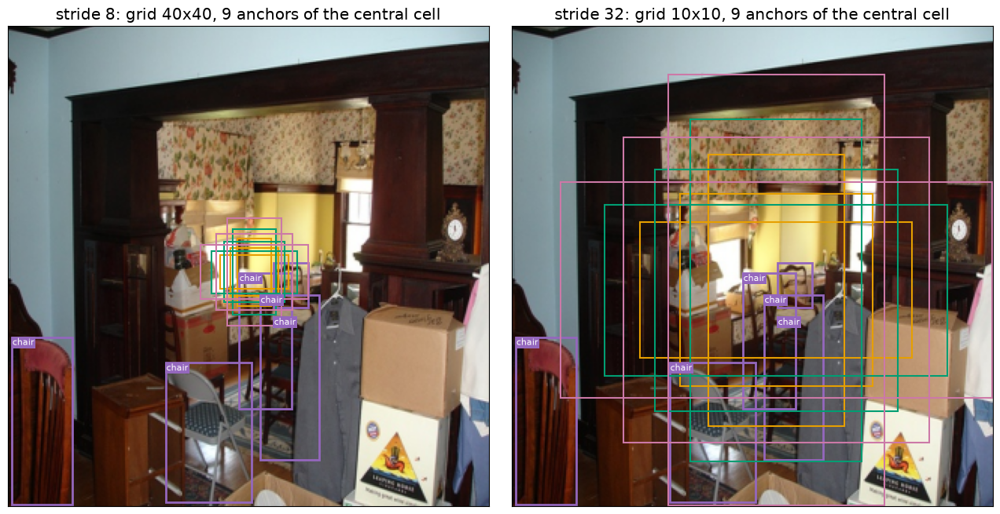

In [27]:
SIZE_COLORS = ['#E69F00', '#009E73', '#CC79A7']   # 3 размера на уровне

image, target = det_val_set[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, stride in zip(axes, [8, 32]):
    show_detections(ax, image, target['boxes'], target['labels'])
    grid = DET_SIZE // stride
    first = sum((DET_SIZE // s) ** 2 * A for s in STRIDES if s < stride) + (grid // 2 * grid + grid // 2) * A
    for a, (x1, y1, x2, y2) in enumerate(anchors[first:first + A].tolist()):
        ax.add_patch(Rectangle((x1 - 0.5, y1 - 0.5), x2 - x1, y2 - y1, fill=False, linewidth=1.5,
                               edgecolor=SIZE_COLORS[a // len(RATIOS)]))
    ax.set_title(f'stride {stride}: grid {grid}x{grid}, {A} anchors of the central cell')
plt.tight_layout()
plt.show()

## 5.1 Matching

Какой anchor за какой объект отвечает? Матрица $\mathrm{IoU}_{ng}$ между $N$ anchors и $G$ GT-боксами картинки:
$$g(n) = \arg\max_g \mathrm{IoU}_{ng}, \qquad
\text{label}(n) = \begin{cases}
g(n), & \max_g \mathrm{IoU}_{ng} \ge 0.5, \\
\text{ignore}, & 0.4 \le \max_g \mathrm{IoU}_{ng} < 0.5, \\
\text{фон}, & \max_g \mathrm{IoU}_{ng} < 0.4.
\end{cases}$$

Пограничные anchors не учат ни как объект, ни как фон. Чтобы объект без хороших anchors не остался без пары, каждому GT дополнительно отдаём anchor с максимальным IoU (**low-quality match**).

In [28]:
BACKGROUND, IGNORE = -1, -2


def match_anchors(anchors, gt_boxes, pos_thr=0.5, neg_thr=0.4):
    # -> (N,): индекс GT-бокса для каждого anchor, BACKGROUND или IGNORE
    if len(gt_boxes) == 0:
        return torch.full((len(anchors),), BACKGROUND)
    iou = box_iou(anchors, gt_boxes)                          # (N, G)
    best_iou, matched = iou.max(dim=1)
    best_gt = matched.clone()
    matched[best_iou < pos_thr] = IGNORE
    matched[best_iou < neg_thr] = BACKGROUND
    low_quality = (iou == iou.max(dim=0).values).any(dim=1)   # anchors, лучшие хотя бы для одного GT
    matched[low_quality] = best_gt[low_quality]
    return matched

In [29]:
from torchvision.models.detection._utils import Matcher

image, target = det_val_set[0]
matched = match_anchors(anchors, target['boxes'])
assert torch.equal(matched, Matcher(0.5, 0.4, allow_low_quality_matches=True)(box_iou(target['boxes'], anchors)))
{'positive': (matched >= 0).sum().item(), 'ignore': (matched == IGNORE).sum().item(),
 'background': (matched == BACKGROUND).sum().item()}

{'positive': 71, 'ignore': 231, 'background': 18823}

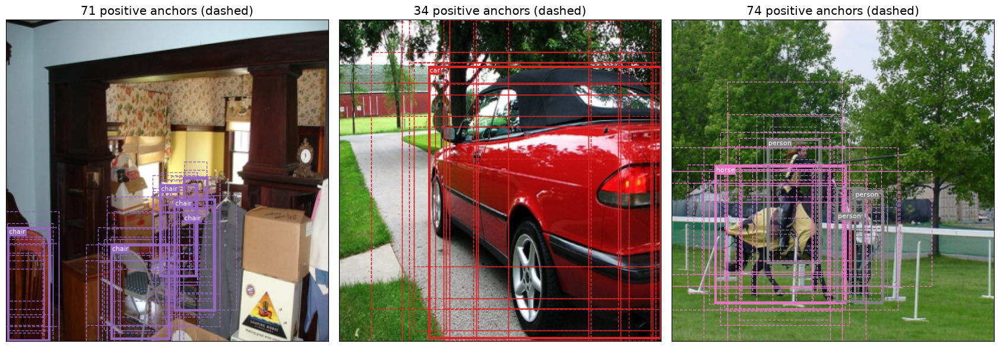

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.8))
for ax, i in zip(axes, [0, 1, 2]):
    image, target = det_val_set[i]
    matched = match_anchors(anchors, target['boxes'])
    show_detections(ax, image, target['boxes'], target['labels'], linewidth=3)
    for n in (matched >= 0).nonzero().flatten().tolist():
        x1, y1, x2, y2 = anchors[n].tolist()
        ax.add_patch(Rectangle((x1 - 0.5, y1 - 0.5), x2 - x1, y2 - y1, fill=False, linestyle='--', linewidth=1,
                               edgecolor=CLASS_COLORS[target['labels'][matched[n]]]))
    ax.set_title(f'{(matched >= 0).sum().item()} positive anchors (dashed)')
plt.tight_layout()
plt.show()

### \*Какие anchors нужны

Хороший набор anchors — такой, что почти у каждого GT есть anchor с $\mathrm{IoU} \ge 0.5$. Проверим на 1000 фото train (боксы в масштабе $320 \times 320$) по размерам объектов, как в COCO: маленькие — $\sqrt{wh} < 32$, средние — до 96, крупные — больше.

In [31]:
def resized_boxes(ann, size=DET_SIZE):
    return ann['boxes'] * torch.tensor([size / ann['width'], size / ann['height']] * 2)


def anchor_row(name, anchors, image_ids=det_ids['train'][:1000]):
    best, sides, n_pos = [], [], []
    for image_id in image_ids:
        gt_boxes = resized_boxes(annotations[image_id])
        best.append(box_iou(anchors, gt_boxes).max(dim=0).values)   # лучший anchor для каждого GT
        sides.append(box_area(gt_boxes).sqrt())
        n_pos.append((match_anchors(anchors, gt_boxes) >= 0).sum().item())
    best, sides = torch.cat(best), torch.cat(sides)
    covered = [(best[m] >= 0.5).float().mean().item() for m in [sides < 32, (sides >= 32) & (sides < 96), sides >= 96]]
    print(f'{name:<32}{len(anchors):>7}{(best >= 0.5).float().mean():>9.3f}' + ''.join(f'{c:>9.3f}' for c in covered)
          + f'{np.mean(n_pos):>11.1f}')


print(f'{"anchors":<32}{"N":>7}{"all":>9}{"small":>9}{"medium":>9}{"large":>9}{"pos/img":>11}')
all_sizes = [size for s in STRIDES for size in level_sizes(s)]
anchor_row('one level, stride 16, 3 sizes', make_anchors(DET_SIZE // 16, 16, level_sizes(16), RATIOS))
anchor_row('one level, stride 16, 12 sizes', make_anchors(DET_SIZE // 16, 16, all_sizes, RATIOS))
anchor_row('pyramid, strides 8-64 (ours)', anchors)

anchors                               N      all    small   medium    large    pos/img
one level, stride 16, 3 sizes      3600    0.414    0.000    0.659    0.346       42.9
one level, stride 16, 12 sizes    14400    0.852    0.297    0.903    0.986      236.1
pyramid, strides 8-64 (ours)      19125    0.875    0.419    0.916    0.986       70.0


Один уровень с тремя размерами покрывает 41% объектов и ни одного мелкого. Все 12 размеров на одной сетке stride 16 поднимают покрытие до 85%, но положительных anchors становится 236 на фото — в основном почти одинаковые боксы у крупных объектов. Пирамида покрывает даже чуть больше (88%) при 70 положительных на фото: крупные anchors стоят на редкой сетке. Хуже всего покрыты мелкие объекты (42%): самый маленький anchor — $32 \times 32$, а у объекта $16 \times 16$ с ним IoU всего $0.25$. Такому объекту matching всё равно отдаёт лучший anchor (low-quality match, раздел 5.1).

---
# 6. Детектор: ResNet18 + FPN + головы

![detector](figures/detector.svg)

- **backbone** — ResNet18, обученный на ImageNet: карты $C_3, C_4, C_5$ со stride 8, 16, 32. С нуля на 2500 фото признаки не выучить, а общие признаки ImageNet переносятся на VOC;
- **FPN** собирает пирамиду, где у каждого уровня и глубокая семантика, и своё разрешение:
$$P_5 = \mathrm{Conv}_{1\times1}(C_5), \qquad P_l = \mathrm{Conv}_{1\times1}(C_l) + \mathrm{Up}_{\times 2}(P_{l+1}), \qquad \tilde P_l = \mathrm{Conv}_{3\times3}(P_l),$$
плюс $\tilde P_6$ — свёртка со stride 2 поверх $\tilde P_5$ для самых крупных объектов. Без $\tilde P_6$ это ровно `torchvision.ops.FeaturePyramidNetwork`;
- **головы** — одни и те же свёртки на каждом уровне: $K$ логитов (независимые sigmoid, без класса «фон») и 4 поправки на anchor. Выходы уровней склеиваются в порядке anchors раздела 5.

In [32]:
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.ops.misc import FrozenBatchNorm2d


class Backbone(nn.Module):
    # ResNet18 с ImageNet -> [C3, C4, C5]: 128, 256, 512 каналов, stride 8, 16, 32
    def __init__(self):
        super().__init__()
        net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1, progress=False, norm_layer=FrozenBatchNorm2d)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool, net.layer1)
        self.stem.requires_grad_(False)   # первые слои — общие признаки (края, текстуры), их не дообучаем
        self.stages = nn.ModuleList([net.layer2, net.layer3, net.layer4])
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))   # нормировка ImageNet
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        self.out_channels = (128, 256, 512)

    def forward(self, x):
        x = self.stem((x - self.mean) / self.std)
        features = []
        for stage in self.stages:
            x = stage(x)
            features.append(x)
        return features

In [33]:
class FPN(nn.Module):
    def __init__(self, in_channels, out_channels=128, extra_level=True):
        super().__init__()
        self.lateral = nn.ModuleList([nn.Conv2d(c, out_channels, 1) for c in in_channels])
        self.output = nn.ModuleList([nn.Conv2d(out_channels, out_channels, 3, padding=1) for _ in in_channels])
        self.extra = nn.Conv2d(out_channels, out_channels, 3, stride=2, padding=1) if extra_level else None

    def forward(self, features):
        # features: [C3, C4, C5] -> [P3, P4, P5(, P6)]
        p = self.lateral[-1](features[-1])
        pyramid = [self.output[-1](p)]
        for c, lateral, output in zip(features[-2::-1], self.lateral[-2::-1], self.output[-2::-1]):
            p = lateral(c) + F.interpolate(p, size=c.shape[-2:], mode='nearest')
            pyramid.insert(0, output(p))
        if self.extra is not None:
            pyramid.append(self.extra(F.relu(pyramid[-1])))
        return pyramid

In [34]:
def to_per_anchor(out, n_values):
    # (B, A * n_values, H, W) -> (B, H * W * A, n_values): порядок (i, j, a), как у make_anchors
    B, _, H, W = out.shape
    return out.view(B, -1, n_values, H, W).permute(0, 3, 4, 1, 2).reshape(B, -1, n_values)

In [35]:
class DetectionHead(nn.Module):
    # одни и те же свёртки на каждом уровне пирамиды
    def __init__(self, channels, n_anchors, n_classes, prior=0.01):
        super().__init__()
        self.n_classes = n_classes
        self.cls = nn.Sequential(nn.Conv2d(channels, channels, 3, padding=1), nn.ReLU(),
                                 nn.Conv2d(channels, channels, 3, padding=1), nn.ReLU(),
                                 nn.Conv2d(channels, n_anchors * n_classes, 3, padding=1))
        self.box = nn.Sequential(nn.Conv2d(channels, channels, 3, padding=1), nn.ReLU(),
                                 nn.Conv2d(channels, channels, 3, padding=1), nn.ReLU(),
                                 nn.Conv2d(channels, n_anchors * 4, 3, padding=1))
        nn.init.constant_(self.cls[-1].bias, -math.log((1 - prior) / prior))   # sigmoid(bias) = prior (раздел 6.1)

    def forward(self, f):
        return to_per_anchor(self.cls(f), self.n_classes), to_per_anchor(self.box(f), 4)

In [36]:
class Detector(nn.Module):
    def __init__(self, prior=0.01, channels=128):
        super().__init__()
        self.backbone = Backbone()
        self.fpn = FPN(self.backbone.out_channels, channels)
        self.head = DetectionHead(channels, A, K, prior)

    def forward(self, x):
        cls_logits, box_deltas = zip(*(self.head(p) for p in self.fpn(self.backbone(x))))
        return torch.cat(cls_logits, dim=1), torch.cat(box_deltas, dim=1)   # уровни в порядке anchors

In [37]:
model = Detector()
with torch.no_grad():
    cls_logits, box_deltas = model(torch.rand(2, 3, DET_SIZE, DET_SIZE))
assert cls_logits.shape[1] == len(anchors)

# порядок (i, j, a): разложим anchors уровня stride 16 в раскладку выхода свёртки и вернём обратно
grid, first = DET_SIZE // 16, (DET_SIZE // 8) ** 2 * A
level = anchors[first:first + grid * grid * A]
as_conv = level.view(grid, grid, A * 4).permute(2, 0, 1)[None]
assert torch.equal(to_per_anchor(as_conv, 4)[0], level)
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
cls_logits.shape, box_deltas.shape, f'{n_trainable:,} trainable of {sum(p.numel() for p in model.parameters()):,} params'

(torch.Size([2, 19125, 20]),
 torch.Size([2, 19125, 4]),
 '12,554,840 trainable of 12,711,704 params')

## 6.1 Focal loss

На фото — десятки положительных anchors из 19 тысяч (раздел 5): даже «лёгкий» фон с $p \approx 0$ в сумме забивает градиент BCE. $p_t = p$ для положительного таргета и $1 - p$ для отрицательного:
$$\mathrm{BCE} = -\log p_t, \qquad \mathrm{FL} = -\alpha_t\, (1 - p_t)^\gamma \log p_t, \qquad \gamma = 2, \;\; \alpha = 0.25.$$
Множитель $(1 - p_t)^\gamma$ гасит loss уверенно классифицированных примеров: при $p_t = 0.9$ — в 100 раз, при $p_t = 0.99$ — в $10^4$ раз.

**Инициализация**: bias последнего слоя cls-головы $b = -\log\frac{1 - \pi}{\pi}$, $\pi = 0.01$ — в начале все вероятности $\approx 0.01$, сеть сразу «говорит фон».

In [38]:
def focal_loss_sigmoid(logits, targets, alpha=0.25, gamma=2.0):
    p = torch.sigmoid(logits)
    ce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
    p_t = p * targets + (1 - p) * (1 - targets)
    alpha_t = alpha * targets + (1 - alpha) * (1 - targets)
    return alpha_t * (1 - p_t) ** gamma * ce


torch.manual_seed(0)
logits_demo, targets_demo = torch.randn(100, K) * 3, (torch.rand(100, K) < 0.1).float()
torch.allclose(focal_loss_sigmoid(logits_demo, targets_demo),
               sigmoid_focal_loss(logits_demo, targets_demo, reduction='none'), atol=1e-6)

True

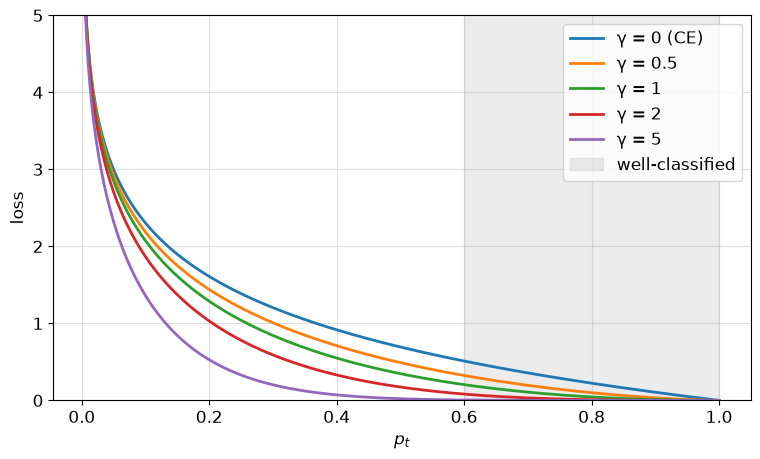

In [39]:
p_t = torch.linspace(0.005, 1, 400)
plt.figure(figsize=(9, 5))
for gamma in [0, 0.5, 1, 2, 5]:
    plt.plot(p_t, -(1 - p_t) ** gamma * torch.log(p_t), linewidth=2, label=f'γ = {gamma}' + (' (CE)' if gamma == 0 else ''))
plt.axvspan(0.6, 1, color='gray', alpha=0.15, label='well-classified')
plt.xlabel('$p_t$')
plt.ylabel('loss')
plt.ylim(0, 5)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

## 6.2 Таргеты и loss

Matching не зависит от весов сети, поэтому таргеты каждого anchor считаем в `collate_fn`, на CPU: класс (индекс класса GT, `BACKGROUND` или `IGNORE`) и поправки $t = \mathrm{encode}(\text{GT}, \text{anchor})$. Anchors, доставшиеся `difficult`-объектам, — `IGNORE`: сеть не наказывают ни за находку, ни за пропуск.

$$L = \frac{1}{N_{\text{pos}}} \Big( \sum_{n \ne \text{ignore}} \sum_{k=1}^{K} \mathrm{FL}(z_{nk}, y_{nk}) \;+\; \sum_{n \in \text{pos}} \|\hat t_n - t_n\|_1 \Big)$$

In [40]:
def anchor_targets(anchors, target):
    matched = match_anchors(anchors, target['boxes'])
    pos = matched >= 0
    labels = matched.clone()
    labels[pos] = target['labels'][matched[pos]]
    labels[pos & target['difficult'][matched.clamp(min=0)]] = IGNORE
    deltas = torch.zeros(len(anchors), 4)
    deltas[pos] = encode(target['boxes'][matched[pos]], anchors[pos])
    return labels, deltas


def make_detection_collate(anchors):
    def collate(batch):
        images, targets = zip(*batch)
        labels, deltas = zip(*(anchor_targets(anchors, t) for t in targets))
        return torch.stack(images), torch.stack(labels), torch.stack(deltas), list(targets)
    return collate


def detection_loss(cls_logits, box_deltas, labels, deltas):
    pos, valid = labels >= 0, labels != IGNORE
    cls_targets = F.one_hot(labels.clamp(min=0), K).float() * pos[..., None]   # у фона все K таргетов — 0
    n_pos = pos.sum().clamp(min=1)
    cls_loss = sigmoid_focal_loss(cls_logits[valid], cls_targets[valid], reduction='sum') / n_pos
    box_loss = F.l1_loss(box_deltas[pos], deltas[pos], reduction='sum') / n_pos
    return cls_loss, box_loss

In [41]:
det_train_loader = DataLoader(det_train_set, batch_size=BATCH_SIZE, shuffle=True, collate_fn=make_detection_collate(anchors),
                              generator=torch.Generator().manual_seed(0))
images, labels, deltas, targets = next(iter(det_train_loader))
images.shape, labels.shape, deltas.shape, (labels >= 0).sum(dim=1).float().mean().item()

(torch.Size([16, 3, 320, 320]),
 torch.Size([16, 19125]),
 torch.Size([16, 19125, 4]),
 40.1875)

Сколько loss приходится на фоновые anchors в самом начале обучения — с обычной инициализацией ($\pi = 0.5$, bias 0) и с $\pi = 0.01$, для BCE и focal loss:

In [42]:
pos, valid = labels >= 0, labels != IGNORE
cls_targets = F.one_hot(labels.clamp(min=0), K).float() * pos[..., None]
print(f'{"init":<12}{"loss":<7}{"loss / N_pos":>13}{"background share":>18}')
for prior in [0.5, 0.01]:
    set_seed(0)
    with torch.no_grad():
        logits = Detector(prior=prior)(images)[0]
    for name, loss_fn in [('BCE', F.binary_cross_entropy_with_logits), ('focal', sigmoid_focal_loss)]:
        per_anchor = loss_fn(logits, cls_targets, reduction='none').sum(dim=-1) * valid   # (B, N)
        share = per_anchor[labels == BACKGROUND].sum() / per_anchor.sum()
        print(f'{"π = " + str(prior):<12}{name:<7}{per_anchor.sum() / pos.sum():>13.1f}{share:>18.3f}')

init        loss    loss / N_pos  background share
π = 0.5     BCE           6556.2             0.998
π = 0.5     focal         1230.2             0.998
π = 0.01    BCE             99.7             0.952
π = 0.01    focal            1.1             0.006


С обычной инициализацией почти весь loss — от фона: 99.8% и у BCE, и у focal loss. Старт с $\pi = 0.01$ сразу делает фон уверенным «нет», но у BCE фон всё равно даёт 95% loss: лёгких примеров десятки тысяч, и каждый вносит немного. Только вместе — $\pi = 0.01$ и focal loss — доля фона падает до 0.6%, и градиент идёт от объектов.

## 6.3 Обучение

Детектор учится десятки минут, а на семинаре ноутбук делит машину с другими процессами. При `TRAIN = False` веса и лог обучения берутся из `checkpoints/` — их сохранил этот же код при `FAST_MODE = True`; если файла нет или `TRAIN = True`, модель учится с нуля и сохраняется.

In [43]:
def fit_or_load(name, model, train_fn, verbose=True, only=None):
    # train_fn(model) учит модель на месте и возвращает лог — список строк;
    # only — префиксы ключей state_dict, которые сохраняем (остальное — готовые замороженные веса)
    path = os.path.join(CKPT_DIR, f'{name}.pt' if FAST_MODE else f'{name}_full.pt')
    if not TRAIN and os.path.exists(path):
        checkpoint = torch.load(path, map_location=device)
        model.load_state_dict(checkpoint['state_dict'], strict=only is None)
        log, note = checkpoint['log'], f"loaded {path} (training took {checkpoint['seconds']:.0f} s on {checkpoint['device']})"
    else:
        start = time.time()
        log = train_fn(model)
        seconds = time.time() - start
        os.makedirs(CKPT_DIR, exist_ok=True)
        state = {k: v.cpu().half() if v.is_floating_point() else v.cpu()   # float16: файл вдвое меньше
                 for k, v in model.state_dict().items() if only is None or k.startswith(tuple(only))}
        torch.save({'state_dict': state, 'log': log, 'seconds': seconds, 'device': str(device)}, path)
        note = f'trained in {seconds:.1f} s on {device}, saved to {path}'
    if verbose:
        print('\n'.join(log))
    print(f'{name}: {note}')
    return model.eval()

In [44]:
def train_detector(model, loader, epochs, lr=1e-3):
    # предобученный backbone учим в 10 раз медленнее, чем новые FPN и головы
    backbone = [p for p in model.backbone.parameters() if p.requires_grad]
    new = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith('backbone.')]
    optimizer = torch.optim.AdamW([dict(params=backbone, lr=lr / 10), dict(params=new, lr=lr)], weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[lr / 10, lr], total_steps=epochs * len(loader))
    log = []
    for epoch in range(epochs):
        model.train()
        totals = torch.zeros(2)
        for images, labels, deltas, _ in loader:
            images, labels, deltas = images.to(device), labels.to(device), deltas.to(device)
            cls_loss, box_loss = detection_loss(*model(images), labels, deltas)
            optimizer.zero_grad()
            (cls_loss + box_loss).backward()
            optimizer.step()
            scheduler.step()
            totals += torch.tensor([cls_loss.item(), box_loss.item()])
        cls_avg, box_avg = (totals / len(loader)).tolist()
        log.append(f'epoch {epoch + 1}/{epochs}: cls loss = {cls_avg:.3f}, box loss = {box_avg:.3f}')
    return log

In [45]:
set_seed(0)
detector = fit_or_load('detector', Detector().to(device), lambda m: train_detector(m, det_train_loader, DET_EPOCHS))

epoch 1/20: cls loss = 0.841, box loss = 0.621
epoch 2/20: cls loss = 0.606, box loss = 0.534
epoch 3/20: cls loss = 0.545, box loss = 0.486
epoch 4/20: cls loss = 0.546, box loss = 0.462
epoch 5/20: cls loss = 0.612, box loss = 0.455
epoch 6/20: cls loss = 0.470, box loss = 0.418
epoch 7/20: cls loss = 0.403, box loss = 0.396
epoch 8/20: cls loss = 0.377, box loss = 0.374
epoch 9/20: cls loss = 0.346, box loss = 0.357
epoch 10/20: cls loss = 0.308, box loss = 0.340
epoch 11/20: cls loss = 0.276, box loss = 0.318
epoch 12/20: cls loss = 0.234, box loss = 0.297
epoch 13/20: cls loss = 0.205, box loss = 0.277
epoch 14/20: cls loss = 0.171, box loss = 0.258
epoch 15/20: cls loss = 0.147, box loss = 0.239
epoch 16/20: cls loss = 0.126, box loss = 0.219
epoch 17/20: cls loss = 0.109, box loss = 0.206
epoch 18/20: cls loss = 0.099, box loss = 0.196
epoch 19/20: cls loss = 0.092, box loss = 0.188
epoch 20/20: cls loss = 0.091, box loss = 0.186
detector: loaded ./checkpoints/detector.pt (train

---
# 7. NMS

Выход сети превращаем в кандидатов: для пары (anchor $n$, класс $k$) бокс $\hat b_n = \mathrm{decode}(\hat t_n, a_n)$ и score $\sigma(z_{nk})$; оставляем пары со score $> 0.05$, не больше 1000 лучших на фото.

In [46]:
@torch.no_grad()
def raw_detections(model, images, anchors, score_thr=0.05, top_k=1000):
    # -> по фото dict(boxes, scores, labels), до NMS
    model.eval()
    cls_logits, box_deltas = model(images.to(device))
    out = []
    for logits, t in zip(cls_logits.cpu(), box_deltas.cpu()):
        scores, idx = logits.sigmoid().flatten().topk(top_k)   # пары (anchor, класс): idx = n * K + k
        keep = scores > score_thr
        scores, idx = scores[keep], idx[keep]
        n, k = idx // K, idx % K
        out.append(dict(boxes=decode(t[n], anchors[n]).clamp(0, DET_SIZE), scores=scores, labels=k))
    return out

In [47]:
val_subset = Subset(det_val_set, range(N_VAL_DET))
val_loader = DataLoader(val_subset, batch_size=32, collate_fn=lambda b: tuple(zip(*b)))
raw_val, gt_val = [], []
for images, targets in val_loader:
    raw_val += raw_detections(detector, torch.stack(images), anchors)
    gt_val += [dict(boxes=t['boxes'].as_subclass(torch.Tensor), labels=t['labels'], difficult=t['difficult']) for t in targets]
np.mean([len(d['boxes']) for d in raw_val]), np.mean([len(g['boxes']) for g in gt_val])   # кандидатов и GT на фото

(np.float64(608.876), np.float64(3.164))

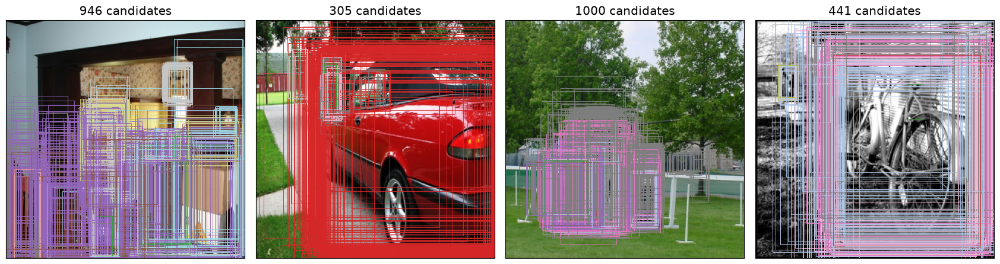

In [48]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
for ax, i in zip(axes, range(4)):
    det = raw_val[i]
    show_detections(ax, val_subset[i][0], det['boxes'], det['labels'], text=False, linewidth=0.6)
    ax.set_title(f'{len(det["boxes"])} candidates')
plt.tight_layout()
plt.show()

Вокруг каждого объекта десятки боксов: соседние anchors и соседние уровни пирамиды тоже «видят» объект. **NMS** (non-maximum suppression) оставляет по одному, жадно:
1. взять бокс с максимальным score и оставить его;
2. выбросить все боксы, у которых IoU с ним больше порога;
3. повторять, пока боксы не кончатся.

![NMS](figures/nms.gif)

In [49]:
def nms_manual(boxes, scores, iou_thr):
    order = scores.argsort(descending=True)
    keep = []
    while len(order) > 0:
        best, rest = order[0], order[1:]
        keep.append(best.item())
        order = rest[box_iou(boxes[best][None], boxes[rest])[0] <= iou_thr]
    return torch.tensor(keep, dtype=torch.long)


det = raw_val[0]
assert torch.equal(nms_manual(det['boxes'], det['scores'], 0.5), nms(det['boxes'], det['scores'], 0.5))
len(det['boxes']), len(nms(det['boxes'], det['scores'], 0.5))

(946, 56)

NMS делают **по классам**: бокс «person» не должен гасить пересекающийся с ним бокс «bicycle». Трюк `batched_nms`: сдвинуть боксы класса $k$ на $k \cdot (\max \text{coord} + 1)$ по обеим осям — боксы разных классов перестают пересекаться, и хватает одного вызова NMS.

In [50]:
def batched_nms_manual(boxes, scores, labels, iou_thr):
    offsets = labels[:, None].float() * (boxes.max() + 1)
    return nms_manual(boxes + offsets, scores, iou_thr)


assert torch.equal(batched_nms_manual(det['boxes'], det['scores'], det['labels'], 0.5),
                   batched_nms(det['boxes'], det['scores'], det['labels'], 0.5))


def postprocess(det, iou_thr=0.5, max_det=100):
    keep = batched_nms(det['boxes'], det['scores'], det['labels'], iou_thr)[:max_det]   # по убыванию score
    return {k: v[keep] for k, v in det.items()}


pred_val = [postprocess(d) for d in raw_val]

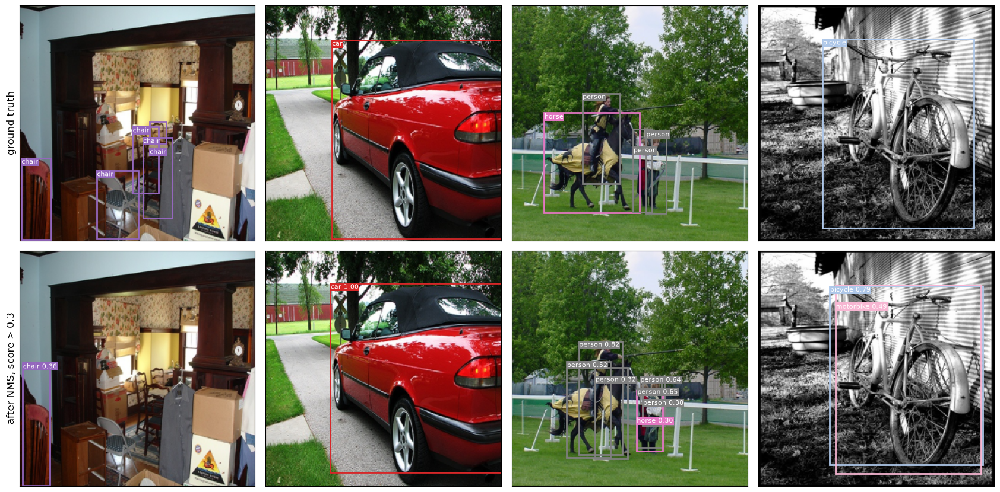

In [51]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8.6))
for col, i in enumerate(range(4)):
    image = val_subset[i][0]
    det = pred_val[i]
    confident = det['scores'] > 0.3
    show_detections(axes[0, col], image, gt_val[i]['boxes'], gt_val[i]['labels'])
    show_detections(axes[1, col], image, det['boxes'][confident], det['labels'][confident], det['scores'][confident])
axes[0, 0].set_ylabel('ground truth')
axes[1, 0].set_ylabel('after NMS, score > 0.3')
plt.tight_layout()
plt.show()

Машину детектор находит уверенно (score 1.00), а из шести стульев в загромождённой комнате — один, со score 0.36. Велосипед получил два бокса разных классов — `bicycle` 0.79 и `motorbike` 0.49: NMS работает внутри класса и такие пары не гасит. На сцене с лошадью вокруг всадника остались лишние боксы `person`, а лошадь найдена со score 0.30 и не на своём месте. Сколько таких ошибок каждого вида — в разделе 9.1.

---
# 8\*. GIoU

$1 - \mathrm{IoU}$ как loss для боксов плох тем, что у непересекающихся боксов $\mathrm{IoU} = 0$ при любом расстоянии — градиента нет. **GIoU** (Rezatofighi et al., 2019):
$$\mathrm{GIoU}(A, B) = \mathrm{IoU}(A, B) - \frac{|C \setminus (A \cup B)|}{|C|} \in (-1, 1],$$
$C$ — наименьший бокс, содержащий $A$ и $B$. У непересекающихся боксов GIoU растёт по мере сближения. В `torchvision.ops`: `generalized_box_iou_loss`, а также DIoU / CIoU (`distance_box_iou_loss`, `complete_box_iou_loss`) — со штрафом за расстояние между центрами и разницу пропорций.

In [52]:
from torchvision.ops import generalized_box_iou


def giou_elementwise(a, b):
    # a, b: (N, 4) — попарно по строкам
    lt, rb = torch.maximum(a[:, :2], b[:, :2]), torch.minimum(a[:, 2:], b[:, 2:])
    inter = (rb - lt).clamp(min=0).prod(dim=1)
    union = box_area(a) + box_area(b) - inter
    hull = (torch.maximum(a[:, 2:], b[:, 2:]) - torch.minimum(a[:, :2], b[:, :2])).prod(dim=1)   # площадь C
    return inter / union - (hull - union) / hull


moves = torch.linspace(-30, 60, 181)
box_a = torch.tensor([[0., 0., 20., 20.]]).expand(len(moves), 4)
box_b = torch.tensor([[0., 0., 20., 20.]]) + torch.stack([moves, torch.zeros_like(moves)] * 2, dim=1)
giou = giou_elementwise(box_a, box_b)
assert torch.allclose(giou, generalized_box_iou(box_a, box_b).diagonal(), atol=1e-6)

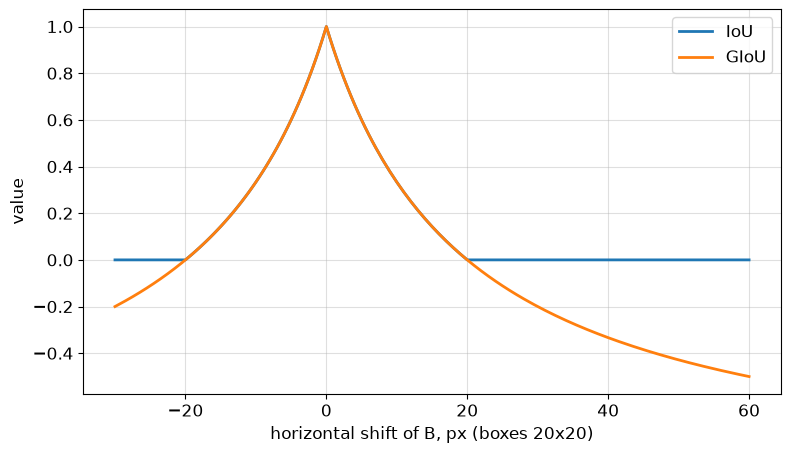

In [53]:
plt.figure(figsize=(9, 5))
plt.plot(moves, box_iou(box_a[:1], box_b)[0], linewidth=2, label='IoU')
plt.plot(moves, giou, linewidth=2, label='GIoU')
plt.xlabel('horizontal shift of B, px (boxes 20x20)')
plt.ylabel('value')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

---
# Семинар 6. Оценка детектора и сегментация

# 9. AP и mAP

Предсказание (бокс, класс, score) — **TP**, если есть GT того же класса с $\mathrm{IoU} \ge 0.5$, ещё не занятый более уверенным предсказанием; иначе — **FP**. Незанятые GT — **FN**. Сортируем предсказания класса по убыванию score и опускаем порог сверху вниз:
$$\mathrm{precision}_k = \frac{\mathrm{TP}_k}{k}, \qquad \mathrm{recall}_k = \frac{\mathrm{TP}_k}{N_{\text{GT}}},$$
$\mathrm{TP}_k$ — число TP среди первых $k$ предсказаний.

**AP** — площадь под PR-кривой, у которой precision заменена «огибающей справа»:
$$p_{\text{interp}}(r) = \max_{r' \ge r} p(r'), \qquad \mathrm{AP} = \sum_k (r_k - r_{k-1})\, p_{\text{interp}}(r_k).$$

- **mAP@0.5** — среднее AP по классам при пороге IoU 0.5 (Pascal VOC); `difficult`-объекты не входят в $N_{\text{GT}}$, а предсказания на них не считаются ни TP, ни FP;
- **mAP@[.5:.95]** — ещё и среднее по порогам $0.5, 0.55, \dots, 0.95$ (COCO): награждает точную локализацию.

In [54]:
# один класс, 3 GT-объекта, 6 предсказаний — уже по убыванию score
toy_scores = torch.tensor([0.95, 0.9, 0.8, 0.6, 0.5, 0.3])
toy_tp = torch.tensor([1, 0, 1, 0, 0, 1])   # результат сопоставления с GT
toy_n_gt = 3

tp_cum = toy_tp.cumsum(0)
toy_precision = tp_cum / torch.arange(1, len(toy_tp) + 1)
toy_recall = tp_cum / toy_n_gt
print(f'{"score":>6}{"TP":>4}{"precision":>11}{"recall":>8}')
for s, tp, p, r in zip(toy_scores.tolist(), toy_tp.tolist(), toy_precision.tolist(), toy_recall.tolist()):
    print(f'{s:>6.2f}{tp:>4}{p:>11.3f}{r:>8.3f}')

 score  TP  precision  recall
  0.95   1      1.000   0.333
  0.90   0      0.500   0.333
  0.80   1      0.667   0.667
  0.60   0      0.500   0.667
  0.50   0      0.400   0.667
  0.30   1      0.500   1.000


In [55]:
def average_precision(tp, n_gt):
    # tp: (P,) из 0 и 1, предсказания по убыванию score
    if n_gt == 0:
        return float('nan')
    tp_cum = tp.float().cumsum(0)
    precision = tp_cum / torch.arange(1, len(tp) + 1)
    recall = tp_cum / n_gt
    envelope = precision.flip(0).cummax(0).values.flip(0)   # максимум precision справа
    recall_prev = torch.cat([torch.zeros(1), recall[:-1]])
    return ((recall - recall_prev) * envelope).sum().item()


average_precision(toy_tp, toy_n_gt)   # 1/3 * 1 + 1/3 * 2/3 + 1/3 * 1/2

0.7222222089767456

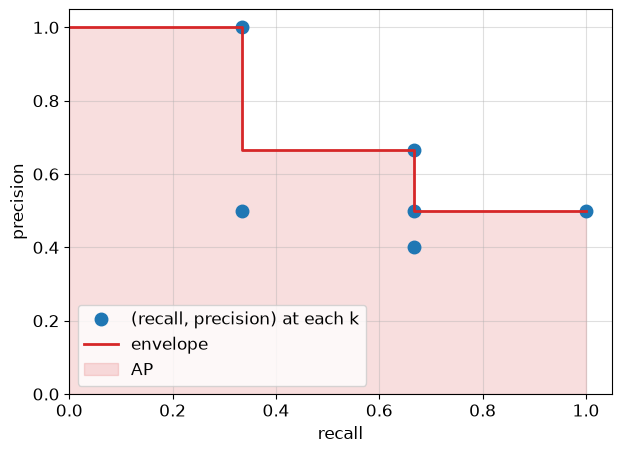

In [56]:
r = torch.cat([torch.zeros(1), toy_recall])
envelope = toy_precision.flip(0).cummax(0).values.flip(0)
plt.figure(figsize=(7, 5))
plt.plot(toy_recall, toy_precision, 'o', markersize=9, label='(recall, precision) at each k')
plt.step(r, torch.cat([envelope[:1], envelope]), where='pre', color='tab:red', linewidth=2, label='envelope')
plt.fill_between(r, torch.cat([envelope[:1], envelope]), step='pre', color='tab:red', alpha=0.15, label='AP')
plt.xlabel('recall')
plt.ylabel('precision')
plt.xlim(0, 1.05)
plt.ylim(0, 1.05)
plt.legend(loc='lower left')
plt.grid(True, alpha=0.4)
plt.show()

По датасету: предсказания одного класса сопоставляем с GT отдельно на каждом фото (жадно, по убыванию score), потом все TP/FP класса сортируем по score вместе и считаем AP.

In [57]:
def match_detections(iou, difficult, iou_thr):
    # iou: (P, G), предсказания по убыванию score -> tp (P,) и keep (P,): попадание в difficult GT не считаем
    tp, keep = torch.zeros(iou.shape[0]), torch.ones(iou.shape[0], dtype=torch.bool)
    taken = torch.zeros(iou.shape[1], dtype=torch.bool)
    for i in range(iou.shape[0]):
        candidates = iou[i].masked_fill(taken, -1.0)
        if len(candidates) > 0 and candidates.max() >= iou_thr:
            j = candidates.argmax()
            if difficult[j]:
                keep[i] = False
            else:
                tp[i], taken[j] = 1, True
    return tp, keep

In [58]:
def evaluate_map(predictions, ground_truth, iou_thresholds=(0.5,), n_classes=K):
    # списки dict(boxes, labels[, scores, difficult]) по фото -> AP: (n_classes, число порогов)
    T = len(iou_thresholds)
    scores = [[[] for _ in range(T)] for _ in range(n_classes)]
    tps = [[[] for _ in range(T)] for _ in range(n_classes)]
    n_gt = torch.zeros(n_classes)
    for pred, gt in zip(predictions, ground_truth):
        difficult = gt.get('difficult', torch.zeros(len(gt['labels']), dtype=torch.bool))
        n_gt += torch.bincount(gt['labels'][~difficult], minlength=n_classes)
        for c in pred['labels'].unique().tolist():
            p, g = pred['labels'] == c, gt['labels'] == c
            order = pred['scores'][p].argsort(descending=True)
            iou = box_iou(pred['boxes'][p][order], gt['boxes'][g])
            for t, thr in enumerate(iou_thresholds):
                tp, keep = match_detections(iou, difficult[g], thr)
                tps[c][t].append(tp[keep])
                scores[c][t].append(pred['scores'][p][order][keep])
    ap = torch.zeros(n_classes, T)
    for c in range(n_classes):
        for t in range(T):
            if scores[c][t]:
                order = torch.cat(scores[c][t]).argsort(descending=True)   # одна сортировка по всему датасету
                ap[c, t] = average_precision(torch.cat(tps[c][t])[order], n_gt[c].item())
    return ap

In [59]:
IOU_THRESHOLDS = [round(t, 2) for t in np.arange(0.5, 0.96, 0.05)]

# GT в роли предсказаний со score 1 -> AP = 1 на всех порогах
perfect = [dict(boxes=g['boxes'], labels=g['labels'], scores=torch.ones(len(g['labels']))) for g in gt_val]
assert torch.allclose(evaluate_map(perfect, gt_val, IOU_THRESHOLDS), torch.ones(K, len(IOU_THRESHOLDS)))

In [60]:
start = time.time()
ap = evaluate_map(pred_val, gt_val, IOU_THRESHOLDS)   # (K, 10)
print(f'{time.time() - start:.1f} s, {len(pred_val)} val images\n')
print(f'{"class":<13}{"AP@0.5":>8}{"AP@0.75":>9}{"AP@[.5:.95]":>13}')
for c in ap[:, 0].argsort(descending=True).tolist():
    print(f'{CLASSES[c]:<13}{ap[c, 0]:>8.3f}{ap[c, 5]:>9.3f}{ap[c].mean():>13.3f}')
print(f'{"mAP":<13}{ap[:, 0].mean():>8.3f}{ap[:, 5].mean():>9.3f}{ap.mean():>13.3f}')

5.8 s, 1000 val images

class          AP@0.5  AP@0.75  AP@[.5:.95]
train           0.776    0.454        0.444
bus             0.771    0.538        0.469
cat             0.767    0.433        0.430
horse           0.755    0.389        0.401
dog             0.708    0.398        0.401
motorbike       0.706    0.323        0.358
sofa            0.698    0.327        0.374
bicycle         0.693    0.274        0.341
car             0.684    0.458        0.419
aeroplane       0.670    0.332        0.350
bird            0.644    0.291        0.340
person          0.629    0.202        0.280
cow             0.535    0.204        0.286
diningtable     0.532    0.189        0.243
boat            0.486    0.178        0.210
tvmonitor       0.462    0.241        0.260
sheep           0.433    0.121        0.174
chair           0.333    0.108        0.142
bottle          0.198    0.039        0.074
pottedplant     0.163    0.009        0.049
mAP             0.582    0.275        0.302


mAP@0.5 = 0.582, а при пороге 0.75 — 0.275: объекты детектор находит, но боксы неточные. Лучше всего — крупные объекты характерной формы (`train`, `bus`, `cat`: AP@0.5 около 0.77), хуже всего — мелкие `bottle` и `pottedplant` (0.20 и 0.16), хотя в train их больше, чем автобусов. При пороге 0.75 AP мелких классов почти нулевая (`pottedplant` — 0.009): сдвиг на пару пикселей для них — заметная доля размера (раздел 3).

In [61]:
# порог NMS: слишком низкий гасит соседние объекты, слишком высокий оставляет дубликаты
print(f'{"NMS IoU thr":<12}{"boxes/image (score > 0.3)":>27}{"mAP@0.5":>9}')
for thr in [0.3, 0.5, 0.7, 0.9]:
    preds = [postprocess(d, iou_thr=thr) for d in raw_val]
    n_boxes = np.mean([(p['scores'] > 0.3).sum().item() for p in preds])
    print(f'{thr:<12}{n_boxes:>27.2f}{evaluate_map(preds, gt_val)[:, 0].mean():>9.3f}')
print(f'GT objects per image: {np.mean([len(g["labels"]) for g in gt_val]):.2f}')

NMS IoU thr   boxes/image (score > 0.3)  mAP@0.5
0.3                                3.07    0.578
0.5                                3.77    0.582
0.7                                6.61    0.542
0.9                               29.54    0.344
GT objects per image: 3.16


При пороге 0.5 на фото остаётся 3.8 бокса со score > 0.3 при 3.2 объектах. Порог 0.9 почти ничего не подавляет: 30 боксов на фото, дубликаты становятся ложными срабатываниями, mAP@0.5 падает до 0.34. Порог 0.3 гасит и соседние объекты одного класса, но в VOC они редко сильно перекрываются, поэтому mAP почти не меняется (0.578 против 0.582).

## 9.1 Разбор ошибок

AP показывает, сколько потеряно, но не почему. Каждое предсказание со score > 0.3 относим к одному типу — в порядке убывания score, как при подсчёте AP (предсказания на `difficult`-объектах пропускаем):

| тип | условие |
|---|---|
| TP | IoU ≥ 0.5 со свободным GT того же класса |
| дубликат | IoU ≥ 0.5 с GT того же класса, но он уже занят |
| класс | IoU ≥ 0.5 только с GT другого класса |
| локализация | лучший IoU с GT — от 0.1 до 0.5 |
| фон | IoU < 0.1 со всеми GT |

GT, которые не достались ни одному TP, — пропуски.

In [62]:
def error_breakdown(predictions, ground_truth, n_classes=K, score_thr=0.3, iou_thr=0.5, bg_thr=0.1):
    counts = dict(TP=0, duplicate=0, wrong_class=0, localization=0, background=0, missed=0)
    confusion = torch.zeros(n_classes, n_classes, dtype=torch.long)   # [класс GT, предсказанный класс]
    best = lambda v: v.max().item() if v.numel() else 0.0             # пустой ряд, если GT нет
    for pred, gt in zip(predictions, ground_truth):
        difficult = gt.get('difficult', torch.zeros(len(gt['labels']), dtype=torch.bool))
        keep = pred['scores'] > score_thr
        boxes, labels = pred['boxes'][keep], pred['labels'][keep]   # уже по убыванию score
        on_difficult = box_iou(boxes, gt['boxes'][difficult]).ge(iou_thr).any(dim=1)   # попавшие в difficult не считаем
        boxes, labels = boxes[~on_difficult], labels[~on_difficult]
        gt_boxes, gt_labels = gt['boxes'][~difficult], gt['labels'][~difficult]
        iou = box_iou(boxes, gt_boxes)                               # (P, G)
        taken = torch.zeros(len(gt_boxes), dtype=torch.bool)
        for i in range(len(boxes)):
            same = gt_labels == labels[i]
            free_same = iou[i] * (same & ~taken)
            if best(free_same) >= iou_thr:
                counts['TP'] += 1
                taken[free_same.argmax()] = True
            elif best(iou[i] * same) >= iou_thr:
                counts['duplicate'] += 1
            elif best(iou[i]) >= iou_thr:
                counts['wrong_class'] += 1
                confusion[gt_labels[iou[i].argmax()], labels[i]] += 1
            elif best(iou[i]) >= bg_thr:
                counts['localization'] += 1
            else:
                counts['background'] += 1
        counts['missed'] += (~taken).sum().item()
    return counts, confusion

In [63]:
counts, confusion = error_breakdown(pred_val, gt_val)
print(f"GT objects (not difficult): {counts['TP'] + counts['missed']}, predictions with score > 0.3: "
      f"{sum(v for k, v in counts.items() if k != 'missed')}")
counts

GT objects (not difficult): 2529, predictions with score > 0.3: 3645


{'TP': 1599,
 'duplicate': 170,
 'wrong_class': 596,
 'localization': 917,
 'background': 363,
 'missed': 930}

In [64]:
# кого с кем путает: ошибки класса, [GT -> предсказание]
pairs = sorted(((confusion[g, p].item(), CLASSES[g], CLASSES[p]) for g in range(K) for p in range(K) if confusion[g, p] > 0),
               reverse=True)
for n, g, p in pairs[:8]:
    print(f'{g:>12} -> {p:<12}{n:>4}')

         dog -> cat           28
      person -> chair         17
         cow -> horse         17
        sofa -> chair         16
       sheep -> cow           15
   motorbike -> bicycle       15
       horse -> cow           15
         dog -> person        15


Верных среди 3645 уверенных предсказаний — 1599, меньше половины. Больше всего ошибок локализации (917): бокс рядом с объектом, но IoU < 0.5 — то же, что показало падение AP при пороге 0.75. Дальше — путаница классов (596) между похожими: собака → кошка, корова ↔ лошадь, мотоцикл → велосипед; человек на стуле становится стулом. На пустом фоне детектор срабатывает редко (363 раза). Пропущено 930 из 2529 объектов — больше трети; хуже всего AP у классов с мелкими объектами (раздел 9).

---
# 10. Семантическая сегментация VOC

Попиксельно размечены 422 фото VOC 2007 (`ImageSets/Segmentation`; val целиком лежит в val детекции, детектор его не видел). Две маски на фото, обе — PNG с палитрой, где значение пикселя — номер:
- `SegmentationClass`: $0$ — фон, $c + 1$ — класс $c$ (порядок `CLASSES`), $255$ — граница объектов и неразмеченное: **не учитывать** ни в loss, ни в метриках;
- `SegmentationObject`: номер объекта, $0$ — фон, $255$ — граница.

In [65]:
def voc_colormap(n=256):
    # стандартная палитра VOC: цвет номера i — его биты, разложенные по каналам R, G, B
    cmap = np.zeros((n, 3))
    for i in range(n):
        c, rgb = i, [0, 0, 0]
        for j in range(8):
            for ch in range(3):
                rgb[ch] |= ((c >> ch) & 1) << (7 - j)
            c >>= 3
        cmap[i] = rgb
    return cmap / 255


SEG_CMAP = ListedColormap(voc_colormap())   # imshow(..., vmin=0, vmax=255): цвета как в PNG VOC
INSTANCE_COLORS = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#999999']
INSTANCE_CMAP = ListedColormap(['black'] + [INSTANCE_COLORS[k % 8] for k in range(254)] + [voc_colormap()[255]])

seg_ids = {split: read_ids('Segmentation', split) for split in ['train', 'val']}
{split: len(ids) for split, ids in seg_ids.items()}

{'train': 209, 'val': 213}

In [66]:
class VOCSegmentation(Dataset):
    # (image, target): target — dict с semantic и instances, обе маски (H, W)
    def __init__(self, image_ids, transforms):
        self.image_ids, self.transforms = image_ids, transforms

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, i):
        image_id = self.image_ids[i]
        image = tv_tensors.Image(read_image(os.path.join(VOC_ROOT, 'JPEGImages', f'{image_id}.jpg')))
        masks = {name: tv_tensors.Mask(read_image(os.path.join(VOC_ROOT, folder, f'{image_id}.png'))[0].long())
                 for name, folder in [('semantic', 'SegmentationClass'), ('instances', 'SegmentationObject')]}
        return self.transforms(image, masks)   # маски v2 масштабирует ближайшим соседом


seg_val_tf = v2.Resize((SEG_SIZE, SEG_SIZE))   # картинка остаётся uint8
seg_train_tf = v2.Compose([v2.RandomHorizontalFlip(0.5), v2.RandomResizedCrop((SEG_SIZE, SEG_SIZE), scale=(0.5, 1.0)),
                           v2.RandomPhotometricDistort(p=0.5), v2.ToDtype(torch.float32, scale=True)])
seg_train_set = VOCSegmentation(seg_ids['train'], seg_train_tf)
seg_val_set = VOCSegmentation(seg_ids['val'], seg_val_tf)

val_images, val_targets = zip(*[seg_val_set[i] for i in range(len(seg_val_set))])
val_images = torch.stack(val_images)                                     # (213, 3, 256, 256), uint8
val_semantic = torch.stack([t['semantic'] for t in val_targets]).as_subclass(torch.Tensor)
val_instances = torch.stack([t['instances'] for t in val_targets]).as_subclass(torch.Tensor)
val_images.shape, val_semantic.unique()

(torch.Size([213, 3, 256, 256]),
 tensor([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
          14,  15,  16,  17,  18,  19,  20, 255]))

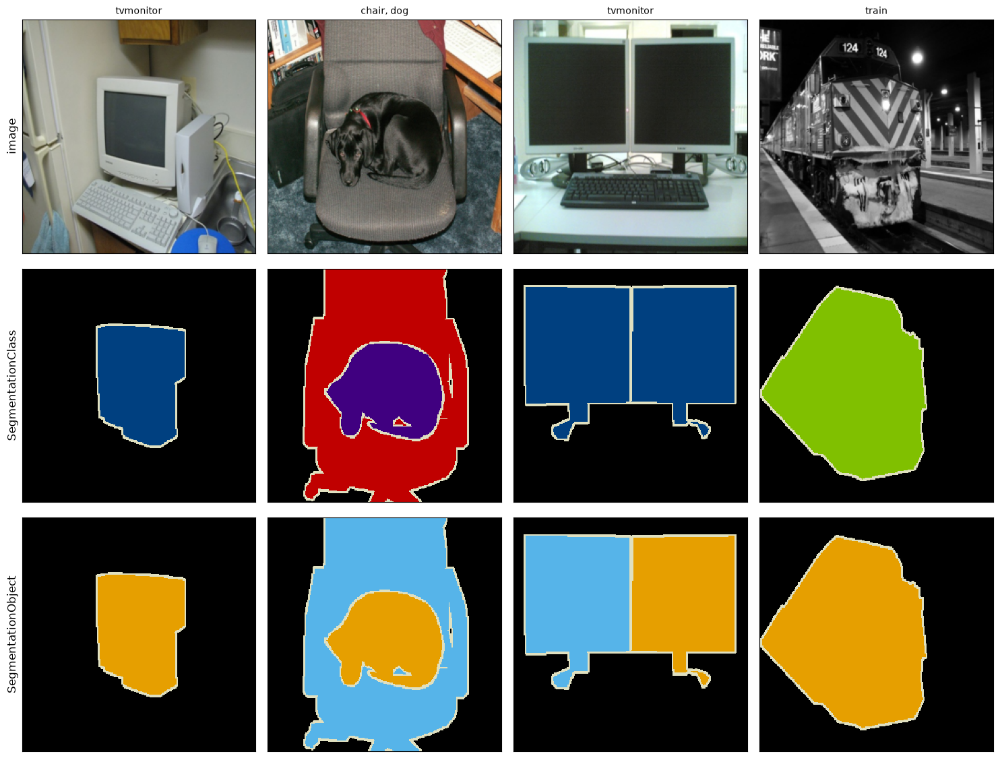

In [67]:
fig, axes = plt.subplots(3, 4, figsize=(15, 11.5))
for col in range(4):
    axes[0, col].imshow(val_images[col].permute(1, 2, 0))
    axes[1, col].imshow(val_semantic[col], cmap=SEG_CMAP, vmin=0, vmax=255, interpolation='nearest')
    axes[2, col].imshow(val_instances[col], cmap=INSTANCE_CMAP, vmin=0, vmax=255, interpolation='nearest')
    names = [CLASSES[c - 1] for c in val_semantic[col].unique().tolist() if 0 < c < 255]
    axes[0, col].set_title(', '.join(names), fontsize=10)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['image', 'SegmentationClass', 'SegmentationObject']):
    ax.set_ylabel(label)
plt.tight_layout()
plt.show()

Попиксельная классификация: логиты $z \in \mathbb R^{B \times (K+1) \times H \times W}$, таргет $y$; пиксели с $y = 255$ из суммы выбрасываются:
$$L_{\text{CE}} = -\frac{1}{|\Omega|} \sum_{(b, i, j) \in \Omega} \log \operatorname{softmax}\big(z_{b, :, i, j}\big)_{y_{bij}}, \qquad \Omega = \{(b, i, j): y_{bij} \ne 255\}.$$

In [68]:
logits = torch.randn(2, K + 1, SEG_SIZE, SEG_SIZE)
target = val_semantic[:2]
valid = target != 255
manual = F.cross_entropy(logits.permute(0, 2, 3, 1)[valid], target[valid])   # только размеченные пиксели
torch.allclose(F.cross_entropy(logits, target, ignore_index=255), manual)

True

In [69]:
pixel_counts = sum(torch.bincount(seg_train_set[i][1]['semantic'].flatten().clamp(max=K + 1), minlength=K + 2)
                   for i in range(len(seg_train_set)))
pixel_share = pixel_counts[:K + 1] / pixel_counts[:K + 1].sum()   # без 255
print(f'background: {pixel_share[0]:.3f}, border 255: {pixel_counts[K + 1] / pixel_counts.sum():.3f} of all pixels')
{CLASSES[c]: round(pixel_share[c + 1].item(), 4) for c in pixel_share[1:].argsort(descending=True).tolist()}

background: 0.664, border 255: 0.059 of all pixels


{'person': 0.1058,
 'cat': 0.0229,
 'bus': 0.0225,
 'dog': 0.0196,
 'sofa': 0.0181,
 'diningtable': 0.0164,
 'train': 0.0154,
 'tvmonitor': 0.0148,
 'bird': 0.0124,
 'chair': 0.0117,
 'horse': 0.0114,
 'motorbike': 0.0111,
 'cow': 0.0102,
 'car': 0.0094,
 'bottle': 0.0088,
 'aeroplane': 0.0068,
 'boat': 0.0067,
 'bicycle': 0.0056,
 'pottedplant': 0.0034,
 'sheep': 0.0029}

---
# 11. Метрики сегментации

Матрица ошибок $M_{ck}$ — число пикселей класса $c$, предсказанных как $k$ (пиксели 255 не входят):
$$\mathrm{IoU}_c = \frac{M_{cc}}{\sum_k M_{ck} + \sum_k M_{kc} - M_{cc}}, \qquad
\mathrm{Dice}_c = \frac{2 M_{cc}}{\sum_k M_{ck} + \sum_k M_{kc}}, \qquad
\text{pixel acc} = \frac{\sum_c M_{cc}}{\sum_{c, k} M_{ck}}.$$

- **mIoU** — среднее $\mathrm{IoU}_c$ по 21 классу, каждый весит одинаково независимо от площади;
- **Dice** — F1 по пикселям класса, $\mathrm{Dice} = \frac{2\,\mathrm{IoU}}{1 + \mathrm{IoU}}$;
- **fg IoU** — IoU «объект vs фон» без учёта класса;
- **small recall** — для объектов из нижней четверти по площади доля их пикселей, отнесённых к правильному классу, в среднем по объектам.

In [70]:
def confusion_matrix(pred, target, n_classes=K + 1, ignore=255):
    # строки — GT, столбцы — предсказание; пиксели ignore не считаем
    valid = target != ignore
    idx = target[valid] * n_classes + pred[valid]
    return torch.bincount(idx, minlength=n_classes ** 2).view(n_classes, n_classes)


def segmentation_metrics(cm):
    tp = cm.diag().float()
    gt, pr = cm.sum(dim=1).float(), cm.sum(dim=0).float()
    iou = tp / (gt + pr - tp)   # nan, если класса нет ни в GT, ни в предсказании
    return dict(pixel_acc=(tp.sum() / cm.sum()).item(),
                fg_iou=(cm[1:, 1:].sum() / (cm.sum() - cm[0, 0])).item(),
                miou=iou.nanmean().item(), iou=iou, dice=2 * tp / (gt + pr))

In [71]:
def objects_of(semantic, instances):
    # объекты фото: (маска, класс 1..20); класс — самый частый в маске объекта
    out = []
    for k in instances.unique().tolist():
        if k in (0, 255):
            continue
        mask = instances == k
        c = semantic[mask].mode().values.item()
        if 0 < c < 255:
            out.append((mask, c))
    return out


val_objects = [objects_of(s, i) for s, i in zip(val_semantic, val_instances)]
object_areas = torch.tensor([m.sum().item() for objs in val_objects for m, _ in objs], dtype=torch.float)
SMALL_AREA = object_areas.quantile(0.25).item()


def small_object_recall(pred):
    recalls = [(pred[n][mask] == c).float().mean() for n, objs in enumerate(val_objects)
               for mask, c in objs if mask.sum() < SMALL_AREA]
    return torch.stack(recalls).mean().item()


len(object_areas), SMALL_AREA

(582, 546.75)

In [72]:
def print_seg_table(results):
    print(f'{"model":<26}{"pixel acc":>10}{"fg IoU":>8}{"mIoU":>7}{"small recall":>14}')
    for name, m in results.items():
        print(f'{name:<26}{m["pixel_acc"]:>10.3f}{m["fg_iou"]:>8.3f}{m["miou"]:>7.3f}{m["small_recall"]:>14.3f}')


all_background = torch.zeros_like(val_semantic)
baseline = segmentation_metrics(confusion_matrix(all_background, val_semantic))
baseline['small_recall'] = small_object_recall(all_background)
assert torch.allclose(baseline['dice'], 2 * baseline['iou'] / (1 + baseline['iou']), equal_nan=True)
print_seg_table({'all background': baseline})

model                      pixel acc  fg IoU   mIoU  small recall
all background                 0.738   0.000  0.035         0.000


«Везде фон» даёт pixel accuracy 0.74: три четверти размеченных пикселей — фон. Но mIoU — 0.035: у фона IoU 0.74, у 20 классов 0, а среднее по 21 классу — $0.74 / 21$. Поэтому дальше смотрим на mIoU и fg IoU, а не на долю верных пикселей.

---
# 12. U-Net с предобученным энкодером

Энкодер сжимает картинку и набирает контекст, декодер разжимает обратно; **skip connections** возвращают в декодер карты энкодера того же разрешения — детали границ, потерянные при сжатии:
$$d_l = \mathrm{DoubleConv}\big(\big[\,\mathrm{Up}(d_{l+1}),\; e_l\,\big]\big),$$
$[\cdot, \cdot]$ — конкатенация по каналам. Энкодер — тот же ResNet18 с ImageNet (раздел 6): 209 фото train слишком мало, чтобы учить его с нуля.

Одна поправка к классической схеме. Декодер из случайных весов учит классы медленно: класс приходит с карты $8 \times 8$ через четыре блока декодера, а skip connections с мелкими признаками дают быстрый путь к «объект или фон». Без поправки, на нашем бюджете в сотни шагов, U-Net выучивает «объект или фон» и пару самых частых классов, а остальные не различает. Поэтому к выходу декодера прибавляем **грубые логиты** — свёртку $1 \times 1$ по самой глубокой карте $e_4$, растянутую в 32 раза:
$$\text{logits} = \mathrm{head}(d_0) + \mathrm{Up}_{\times 32}\big(\mathrm{Conv}_{1 \times 1}(e_4)\big).$$
Класс приходит по короткому пути сразу, декодер уточняет границы. Тот же приём — в FCN-8s и DeepLabV3+.

![U-Net](figures/unet.svg)

In [73]:
def conv_bn_relu(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))


def double_conv(c_in, c_out):
    return nn.Sequential(conv_bn_relu(c_in, c_out), conv_bn_relu(c_out, c_out))

In [74]:
class UNet(nn.Module):
    # энкодер ResNet18: e0 (64, /2), e1 (64, /4), e2 (128, /8), e3 (256, /16), e4 (512, /32)
    def __init__(self, n_classes=K + 1, skips=True):
        super().__init__()
        net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1, progress=False, norm_layer=FrozenBatchNorm2d)
        self.encoder = nn.ModuleList([nn.Sequential(net.conv1, net.bn1, net.relu), nn.Sequential(net.maxpool, net.layer1),
                                      net.layer2, net.layer3, net.layer4])
        self.skips = skips
        deep, shallow = (512, 256, 128, 64), (256, 128, 64, 64)
        self.up = nn.ModuleList([nn.ConvTranspose2d(d, s, 2, stride=2) for d, s in zip(deep, shallow)])
        self.dec = nn.ModuleList([double_conv(2 * s if skips else s, s) for s in shallow])
        self.head = nn.Sequential(nn.ConvTranspose2d(64, 32, 2, stride=2), nn.ReLU(), nn.Conv2d(32, n_classes, 1))
        self.coarse = nn.Conv2d(512, n_classes, 1)   # грубые логиты по e4
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = (x - self.mean) / self.std
        features = []
        for stage in self.encoder:
            x = stage(x)
            features.append(x)
        coarse = F.interpolate(self.coarse(x), scale_factor=32, mode='bilinear')
        for up, dec, skip in zip(self.up, self.dec, features[-2::-1]):
            x = up(x)
            x = dec(torch.cat([x, skip], dim=1) if self.skips else x)
        return self.head(x) + coarse   # head: /2 -> полное разрешение

In [75]:
unet = UNet()
names = [name for name, _ in unet.named_modules() if name.count('.') == 1] + ['head', 'coarse']
hooks = [unet.get_submodule(n).register_forward_hook(lambda m, inp, out, n=n: print(f'{n:<10}{tuple(out.shape)}'))
         for n in names]
with torch.no_grad():
    unet(torch.rand(2, 3, SEG_SIZE, SEG_SIZE))
for h in hooks:
    h.remove()
print(f'params: {sum(p.numel() for p in unet.parameters()):,}, '
      f'encoder: {sum(p.numel() for p in unet.encoder.parameters()):,}')

encoder.0 (2, 64, 128, 128)
encoder.1 (2, 64, 64, 64)
encoder.2 (2, 128, 32, 32)
encoder.3 (2, 256, 16, 16)
encoder.4 (2, 512, 8, 8)
coarse    (2, 21, 8, 8)
up.0      (2, 256, 16, 16)
dec.0     (2, 256, 16, 16)
up.1      (2, 128, 32, 32)
dec.1     (2, 128, 32, 32)
up.2      (2, 64, 64, 64)
dec.2     (2, 64, 64, 64)
up.3      (2, 64, 128, 128)
dec.3     (2, 64, 128, 128)
head.0    (2, 32, 256, 256)
head.1    (2, 32, 256, 256)
head.2    (2, 21, 256, 256)
head      (2, 21, 256, 256)
params: 14,326,698, encoder: 11,166,912


### \*Upsampling: шахматный узор

- `nn.ConvTranspose2d(k=2, stride=2)` — обучаемый: каждый входной пиксель «размазывается» ядром $k \times k$ по выходу;
- `nn.Upsample(scale_factor=2, mode='bilinear')` + свёртка — в самом upsampling весов нет.

Если $k$ не делится на stride, окна transposed convolution перекрываются неравномерно:

In [76]:
ones = torch.ones(1, 1, 8, 8)
for k in [2, 3, 4]:
    cover = F.conv_transpose2d(ones, torch.ones(1, 1, k, k), stride=2)   # сколько окон накрывает выходной пиксель
    print(f'kernel {k}, stride 2, interior:\n{cover[0, 0, 4:10, 4:10].int()}\n')

kernel 2, stride 2, interior:
tensor([[1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1]], dtype=torch.int32)

kernel 3, stride 2, interior:
tensor([[4, 2, 4, 2, 4, 2],
        [2, 1, 2, 1, 2, 1],
        [4, 2, 4, 2, 4, 2],
        [2, 1, 2, 1, 2, 1],
        [4, 2, 4, 2, 4, 2],
        [2, 1, 2, 1, 2, 1]], dtype=torch.int32)

kernel 4, stride 2, interior:
tensor([[4, 4, 4, 4, 4, 4],
        [4, 4, 4, 4, 4, 4],
        [4, 4, 4, 4, 4, 4],
        [4, 4, 4, 4, 4, 4],
        [4, 4, 4, 4, 4, 4],
        [4, 4, 4, 4, 4, 4]], dtype=torch.int32)



При $k = 3$ одни выходные пиксели получают вклад от 1 окна, соседние — от 2 или 4: на выходе появляется шахматный узор (Odena et al., 2016). Поэтому в U-Net берут $k = \text{stride} = 2$ или bilinear upsample + свёртку.

---
# 13. Обучение U-Net

Loss — попиксельный cross-entropy без пикселей 255 (раздел 10). Энкодер дообучаем в 10 раз медленнее декодера: его веса уже хороши.

In [77]:
def segmentation_collate(batch):
    images, targets = zip(*batch)
    return torch.stack(images), torch.stack([t['semantic'] for t in targets]).as_subclass(torch.Tensor)


seg_train_loader = DataLoader(seg_train_set, batch_size=BATCH_SIZE, shuffle=True, collate_fn=segmentation_collate,
                              generator=torch.Generator().manual_seed(0))


def ce_loss(logits, target):
    return F.cross_entropy(logits, target, ignore_index=255)

In [78]:
def train_segmentation(model, loader, epochs, loss_fn, lr=1e-3):
    pretrained = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith('encoder.')]
    new = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith('encoder.')]
    groups = [g for g in [dict(params=pretrained, lr=lr / 10), dict(params=new, lr=lr)] if g['params']]
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[g['lr'] for g in groups],
                                                    total_steps=epochs * len(loader))
    log = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for images, target in loader:
            loss = loss_fn(model(images.to(device)), target.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
            total += loss.item()
        if (epoch + 1) % 10 == 0 or epoch == 0:
            log.append(f'epoch {epoch + 1}/{epochs}: loss = {total / len(loader):.4f}')
    return log

In [79]:
@torch.no_grad()
def predict_semantic(forward, images, batch=32):
    # images: uint8 (N, 3, H, W) -> классы пикселей (N, H, W)
    return torch.cat([forward(chunk.to(device).float() / 255).argmax(dim=1).cpu() for chunk in images.split(batch)])


def evaluate_segmentation(forward):
    pred = predict_semantic(forward, val_images)
    metrics = segmentation_metrics(confusion_matrix(pred, val_semantic))
    metrics['small_recall'] = small_object_recall(pred)
    return metrics

In [80]:
set_seed(0)
unet_ce = fit_or_load('unet_ce', UNet().to(device), lambda m: train_segmentation(m, seg_train_loader, SEG_EPOCHS, ce_loss))

epoch 1/40: loss = 2.9293
epoch 10/40: loss = 0.4727
epoch 20/40: loss = 0.2162
epoch 30/40: loss = 0.1313
epoch 40/40: loss = 0.1325
unet_ce: loaded ./checkpoints/unet_ce.pt (training took 558 s on mps)


In [81]:
seg_results = {'all background': baseline, 'U-Net, CE': evaluate_segmentation(unet_ce)}
print_seg_table(seg_results)

model                      pixel acc  fg IoU   mIoU  small recall
all background                 0.738   0.000  0.035         0.000
U-Net, CE                      0.853   0.620  0.345         0.069


### Без skip connections

Та же сеть, но декодер видит только выход энкодера $8 \times 8$ и восстанавливает $256 \times 256$ сам.

In [82]:
set_seed(0)
unet_noskip = fit_or_load('unet_noskip', UNet(skips=False).to(device),
                          lambda m: train_segmentation(m, seg_train_loader, SEG_EPOCHS, ce_loss), verbose=False)
seg_results['U-Net, no skips, CE'] = evaluate_segmentation(unet_noskip)
print_seg_table(seg_results)

unet_noskip: loaded ./checkpoints/unet_noskip.pt (training took 655 s on mps)
model                      pixel acc  fg IoU   mIoU  small recall
all background                 0.738   0.000  0.035         0.000
U-Net, CE                      0.853   0.620  0.345         0.069
U-Net, no skips, CE            0.840   0.539  0.338         0.048


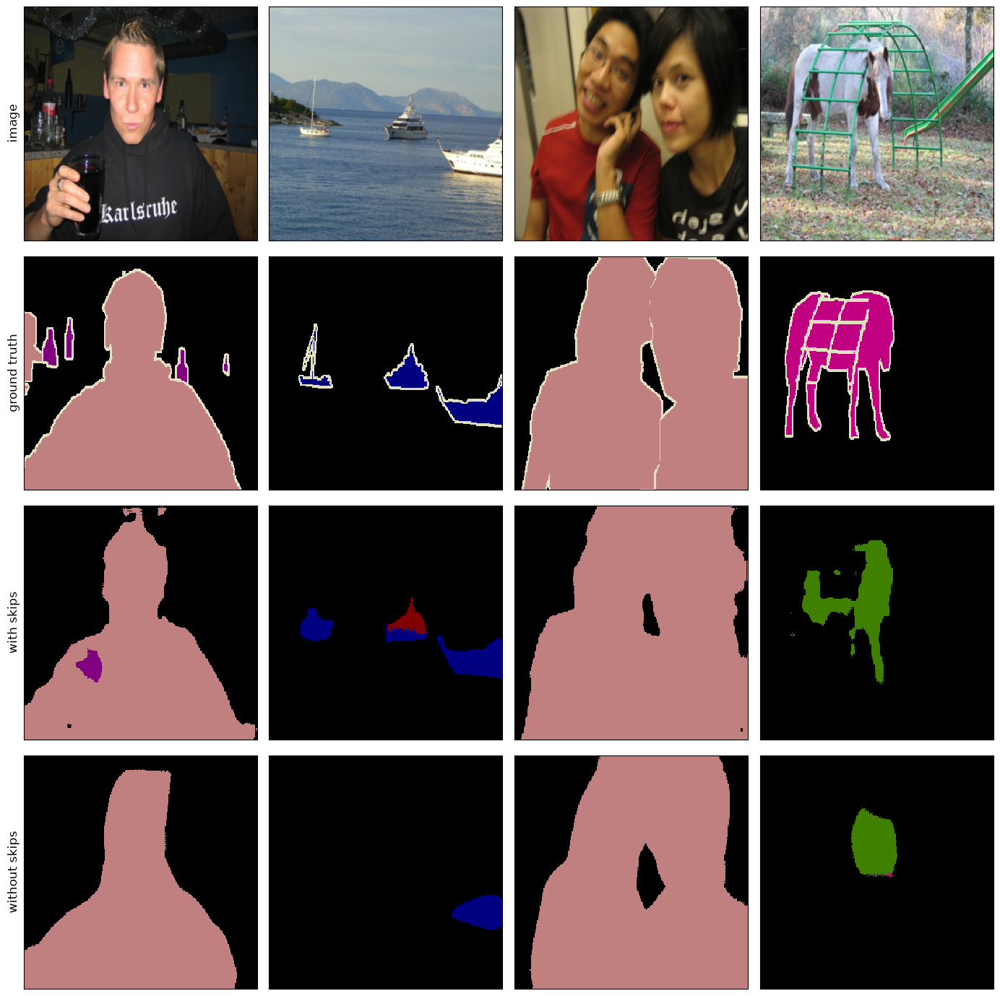

In [83]:
pred_ce, pred_noskip = predict_semantic(unet_ce, val_images), predict_semantic(unet_noskip, val_images)
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for col in range(4):
    i = col + 4
    axes[0, col].imshow(val_images[i].permute(1, 2, 0))
    for row, mask in enumerate([val_semantic[i], pred_ce[i], pred_noskip[i]], start=1):
        axes[row, col].imshow(mask, cmap=SEG_CMAP, vmin=0, vmax=255, interpolation='nearest')
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['image', 'ground truth', 'with skips', 'without skips']):
    ax.set_ylabel(label)
plt.tight_layout()
plt.show()

Без skip connections fg IoU падает с 0.62 до 0.54, а mIoU почти не меняется (0.338 против 0.345). Класс приходит из глубоких карт — по грубым логитам и через декодер, — а skip connections возвращают мелкие детали: точные границы и мелкие объекты (small recall 0.048 против 0.069).

---
# 14. Дисбаланс классов: Dice loss и focal loss

Cross-entropy усредняет по пикселям: класс весит в loss столько, сколько у него пикселей, а фон — большая часть кадра (раздел 10).

**Soft Dice loss** — Dice (раздел 11) с вероятностями вместо жёстких предсказаний, по каждому классу, усреднённый по классам:
$$L_{\text{Dice}} = 1 - \frac{1}{K + 1} \sum_{c=0}^{K} \frac{2 \sum_i p_{ic}\, g_{ic} + \epsilon}{\sum_i p_{ic} + \sum_i g_{ic} + \epsilon},$$
$p_{ic}$ — softmax-вероятность класса $c$ в пикселе $i$, $g_{ic} = \mathbf 1[y_i = c]$, суммы — по размеченным пикселям батча.

**Focal loss** (раздел 6.1) для softmax: $L_{\text{focal}} = -\frac{1}{N} \sum_i (1 - p_{i, y_i})^\gamma \log p_{i, y_i}$ — гасит лёгкие пиксели. На практике часто берут сумму CE + Dice.

In [84]:
def dice_loss(logits, target, eps=1.0, ignore=255):
    valid = (target != ignore)[:, None]                                            # (B, 1, H, W)
    probs = logits.softmax(dim=1) * valid
    onehot = F.one_hot(target.masked_fill(~valid[:, 0], 0), logits.shape[1]).permute(0, 3, 1, 2).float() * valid
    inter = (probs * onehot).sum(dim=(0, 2, 3))                                    # по классам
    denom = probs.sum(dim=(0, 2, 3)) + onehot.sum(dim=(0, 2, 3))
    return 1 - ((2 * inter + eps) / (denom + eps)).mean()


def focal_loss(logits, target, gamma=2.0, ignore=255):
    valid = target != ignore
    log_p = F.log_softmax(logits, dim=1).gather(1, target.masked_fill(~valid, 0)[:, None]).squeeze(1)   # log p_{i, y_i}
    return (-(1 - log_p.exp()) ** gamma * log_p)[valid].mean()


def ce_dice_loss(logits, target):
    return ce_loss(logits, target) + dice_loss(logits, target)


seg_losses = {'CE': ce_loss, 'focal': focal_loss, 'Dice': dice_loss, 'CE + Dice': ce_dice_loss}

In [85]:
logits, target = torch.randn(2, K + 1, 32, 32), val_semantic[:2, ::8, ::8].clone()
assert torch.allclose(focal_loss(logits, target, gamma=0), ce_loss(logits, target))   # gamma = 0 -> CE
confident = F.one_hot(target.clamp(max=K), K + 1).permute(0, 3, 1, 2).float() * 30     # уверенно верные логиты
dice_loss(confident, target).item(), focal_loss(confident, target).item()

(0.0, 0.0)

Куда направлен градиент: доля $\sum |\partial L / \partial z|$ на пикселях объектов — у необученной сети и у сети из раздела 13.

In [86]:
images, target = val_images[:32].to(device).float() / 255, val_semantic[:32].to(device)
objects = (target > 0) & (target < 255)
print(f'object pixels: {objects.float().sum() / (target < 255).sum():.3f} of labeled pixels\n')
print(f'{"model":<14}' + ''.join(f'{name:>11}' for name in seg_losses))
set_seed(0)
for model_name, model in [('init', UNet().to(device).eval()), ('trained, CE', unet_ce)]:
    with torch.no_grad():
        logits = model(images)
    shares = []
    for loss_fn in seg_losses.values():
        z = logits.clone().requires_grad_(True)
        grad, = torch.autograd.grad(loss_fn(z, target), z)
        g = grad.abs().sum(dim=1)   # (B, H, W)
        shares.append((g[objects].sum() / g.sum()).item())
    print(f'{model_name:<14}' + ''.join(f'{s:>11.3f}' for s in shares))

object pixels: 0.290 of labeled pixels

model                  CE      focal       Dice  CE + Dice
init                0.290      0.286      0.743      0.299
trained, CE         0.772      0.842      0.844      0.794


Объекты — 29% размеченных пикселей. В начале обучения CE и focal loss отдают объектам столько же градиента — 0.29: каждый пиксель весит одинаково. Dice отдаёт им 0.74, потому что каждый из 21 класса весит одинаково, а фон — лишь один из них. У обученной модели фон уже выучен, и даже CE отдаёт объектам 0.77 градиента; focal loss гасит лёгкие пиксели фона ещё сильнее — 0.84.

Обучим U-Net с каждым loss на одинаковом **коротком** бюджете: `LOSS_EPOCHS` эпох вместо `SEG_EPOCHS` (раздел 13).

In [87]:
loss_results = {}
for name, loss_fn in seg_losses.items():
    set_seed(0)
    model = fit_or_load(f"unet_{name.lower().replace(' + ', '_')}_short", UNet().to(device),
                        lambda m: train_segmentation(m, seg_train_loader, LOSS_EPOCHS, loss_fn), verbose=False)
    loss_results[name] = evaluate_segmentation(model)
print_seg_table({**loss_results, f'CE, {SEG_EPOCHS} epochs': seg_results['U-Net, CE']})

unet_ce_short: loaded ./checkpoints/unet_ce_short.pt (training took 222 s on mps)
unet_focal_short: loaded ./checkpoints/unet_focal_short.pt (training took 263 s on mps)
unet_dice_short: loaded ./checkpoints/unet_dice_short.pt (training took 235 s on mps)
unet_ce_dice_short: loaded ./checkpoints/unet_ce_dice_short.pt (training took 226 s on mps)
model                      pixel acc  fg IoU   mIoU  small recall
CE                             0.827   0.546  0.278         0.027
focal                          0.821   0.531  0.277         0.044
Dice                           0.738   0.000  0.035         0.000
CE + Dice                      0.837   0.600  0.318         0.039
CE, 40 epochs                  0.853   0.620  0.345         0.069


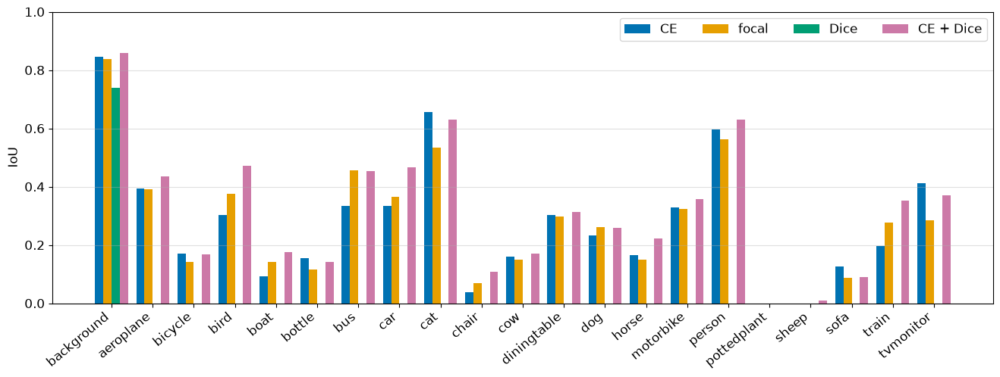

In [88]:
LOSS_COLORS = {'CE': '#0072B2', 'focal': '#E69F00', 'Dice': '#009E73', 'CE + Dice': '#CC79A7'}
fig, ax = plt.subplots(figsize=(16, 5))
width = 0.2
for k, (name, m) in enumerate(loss_results.items()):
    ax.bar(np.arange(K + 1) + (k - 1.5) * width, m['iou'], width, label=name, color=LOSS_COLORS[name])
ax.set_xticks(range(K + 1), ['background'] + CLASSES, rotation=40, ha='right')
ax.set_ylabel('IoU')
ax.set_ylim(0, 1)
ax.legend(ncol=4)
ax.grid(True, axis='y', alpha=0.4)
plt.show()

На коротком бюджете лучше всех CE + Dice: mIoU 0.318 против 0.278 у CE, почти как у CE за полный бюджет (0.345). Focal loss по mIoU не отличается от CE, но находит больше мелких объектов (small recall 0.044 против 0.027).

Dice в одиночку не обучилась: модель везде предсказывает фон — те же 0.738 и 0.035, что у базовой линии (раздел 11). Класс, которого нет в батче, получает в Dice идеальный счёт $\frac{0 + \epsilon}{\sum_i p_{ic} + \epsilon} \to 1$, если его нигде не предсказывать. На старте вероятности размазаны по всем 21 классу, и проще всего погасить все классы, кроме фона. CE каждому пикселю говорит, какой класс правильный, поэтому Dice добавляют к CE, а не ставят вместо него.

---
# 15. Instance segmentation

Семантическая маска не различает объекты одного класса. Два пути к маске каждого объекта:
- **снизу вверх**: semantic-маска → связные компоненты → объекты;
- **сверху вниз**: сначала детекция, потом маска внутри каждого бокса — так устроена Mask R-CNN (раздел 17).

Качество instance-масок: для каждого GT-объекта — лучший IoU с предсказанной маской того же класса.

## 15.1 Связные компоненты

Связная компонента — пиксели маски, между любыми двумя из которых есть путь по соседним пикселям маски (8 соседей). `scipy.ndimage.label` нумерует компоненты за один проход. Компоненты меньше 20 пикселей отбрасываем: шум предсказаний не должен становиться объектами.

In [89]:
def instances_from_semantic(semantic, min_area=20):
    # semantic: (H, W) -> маски (n, H, W) и классы 0..K-1: компоненты каждого класса, не меньше min_area пикселей
    masks, labels = [], []
    for c in semantic.unique().tolist():
        if c in (0, 255):
            continue
        components = torch.from_numpy(ndimage.label((semantic == c).numpy(), structure=np.ones((3, 3)))[0])
        ids = torch.bincount(components.flatten()).ge(min_area).nonzero().flatten()
        ids = ids[ids > 0]
        masks.append(components[None] == ids[:, None, None])
        labels += [c - 1] * len(ids)
    if not labels:
        return torch.zeros(0, *semantic.shape, dtype=torch.bool), torch.zeros(0, dtype=torch.long)
    return torch.cat(masks), torch.tensor(labels)

In [90]:
def gt_instances(n):
    objs = val_objects[n]
    if not objs:
        return torch.zeros(0, SEG_SIZE, SEG_SIZE, dtype=torch.bool), torch.zeros(0, dtype=torch.long)
    return torch.stack([m for m, _ in objs]), torch.tensor([c - 1 for _, c in objs])


def best_mask_iou(pred_masks, pred_labels, gt_masks, gt_labels):
    # для каждого GT-объекта — лучший IoU с предсказанной маской того же класса
    if len(pred_masks) == 0:
        return torch.zeros(len(gt_masks))
    p, g = pred_masks.flatten(1).float(), gt_masks.flatten(1).float()
    inter = g @ p.T
    iou = inter / (g.sum(1)[:, None] + p.sum(1)[None] - inter)
    return iou.masked_fill(gt_labels[:, None] != pred_labels[None], 0).max(dim=1).values

In [91]:
# компоненты идеальной semantic-маски против настоящих объектов
merged, split, ious = [], [], []
for n in range(len(val_images)):
    gt_masks, gt_labels = gt_instances(n)
    cc_masks, cc_labels = instances_from_semantic(val_semantic[n])
    ious.append(best_mask_iou(cc_masks, cc_labels, gt_masks, gt_labels))
    n_gt, n_cc = torch.bincount(gt_labels, minlength=K), torch.bincount(cc_labels, minlength=K)
    if (n_cc < n_gt).any():
        merged.append(n)
    if (n_cc > n_gt).any():
        split.append(n)
len(merged), len(split), len(val_images), torch.cat(ious).mean().item()   # слито, разбито, всего фото, средний IoU объекта

(31, 77, 213, 0.8455561995506287)

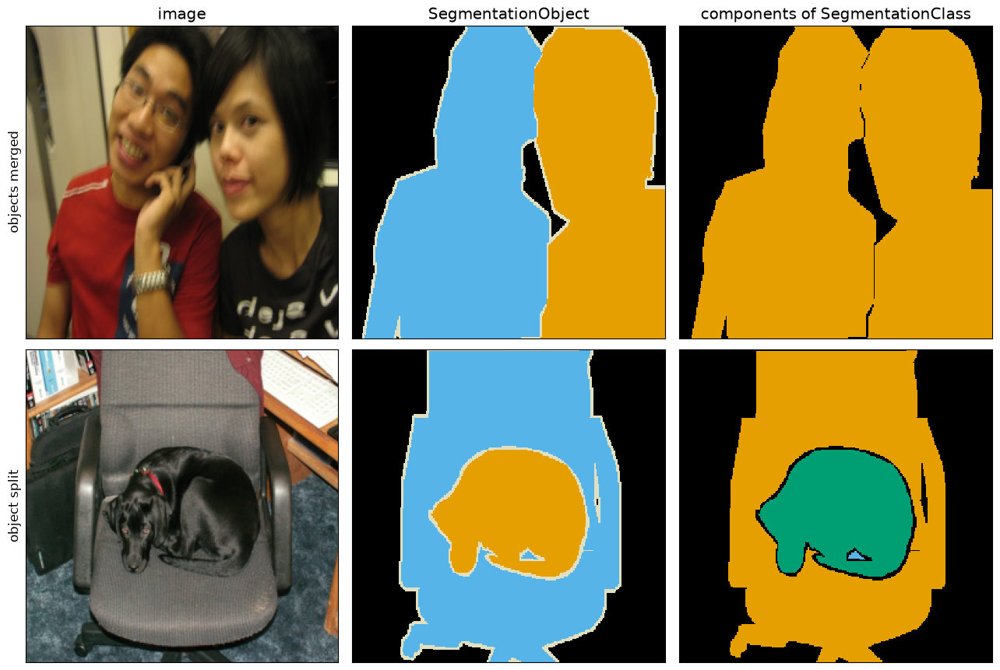

In [92]:
def instance_map(masks):
    ids = torch.zeros(masks.shape[-2:], dtype=torch.long)
    for k, m in enumerate(masks):
        ids[m] = k % 8 + 1
    return ids


fig, axes = plt.subplots(2, 3, figsize=(13, 8.8))
for row, (n, title) in enumerate([(merged[0], 'objects merged'), (split[0], 'object split')]):
    axes[row, 0].imshow(val_images[n].permute(1, 2, 0))
    axes[row, 1].imshow(val_instances[n], cmap=INSTANCE_CMAP, vmin=0, vmax=255, interpolation='nearest')
    axes[row, 2].imshow(instance_map(instances_from_semantic(val_semantic[n])[0]), cmap=INSTANCE_CMAP,
                        vmin=0, vmax=255, interpolation='nearest')
    axes[row, 0].set_ylabel(title)
for ax, title in zip(axes[0], ['image', 'SegmentationObject', 'components of SegmentationClass']):
    ax.set_title(title)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Даже по идеальной разметке компоненты не совпадают с объектами. На 31 фото из 213 касающиеся объекты одного класса слились в одну компоненту, на 77 объект распался на куски: его перекрывает другой объект (собака отрезает кусок стула). Средний лучший IoU объекта с компонентой — 0.85. Где кончается один объект и начинается другой, semantic-маска не знает.

### \*Связные компоненты на тензорах

Метка пикселя — максимум меток соседей $3 \times 3$ (max-pool), только внутри маски; повторяем, пока метки меняются. В итоге у каждой компоненты одна метка. Итераций столько, какова длина самой извилистой компоненты, — поэтому в разделе выше `ndimage.label`.

In [93]:
def connected_components(mask):
    # mask: (H, W) bool -> (H, W) long: 0 — фон, 1..n — компоненты (8-связность)
    labels = torch.arange(1, mask.numel() + 1, dtype=torch.float).view(mask.shape) * mask
    while True:
        spread = F.max_pool2d(labels[None, None], 3, stride=1, padding=1)[0, 0] * mask
        if torch.equal(spread, labels):
            return torch.unique(labels, return_inverse=True)[1]   # перенумеровать: 0, 1, ..., n
        labels = spread


mask = val_semantic[4] == val_semantic[4].unique()[1]                 # одна маска класса
ours = connected_components(mask)
theirs, n_theirs = ndimage.label(mask.numpy(), structure=np.ones((3, 3)))   # 8-связность
pairs = torch.unique(torch.stack([ours.flatten(), torch.from_numpy(theirs).flatten()], dim=1), dim=0)
assert len(pairs) == ours.max() + 1 == n_theirs + 1                   # одно и то же разбиение на компоненты

## 15.2\* Сверху вниз: бокс + маска внутри бокса

Сверху вниз из своих моделей: детектор (раздел 6) разделяет объекты боксами и называет их классы (score > 0.3), маска объекта — пиксели внутри его бокса, которые U-Net (раздел 13) не отнесла к фону. Сравним с компонентами предсказания U-Net по лучшему IoU маски (раздел 15.1).

In [94]:
def top_down_instances(det, semantic):
    # класс — от детектора, форма — от U-Net: пиксели бокса, которые U-Net не отнесла к фону
    masks = []
    for x1, y1, x2, y2 in det['boxes'].round().long().tolist():
        m = torch.zeros_like(semantic, dtype=torch.bool)
        m[y1:y2, x1:x2] = semantic[y1:y2, x1:x2] > 0
        masks.append(m)
    if not masks:
        return torch.zeros(0, *semantic.shape, dtype=torch.bool), det['labels']
    return torch.stack(masks), det['labels']

In [95]:
# детектор на тех же 213 фото: вход 320 x 320, боксы переводим в масштаб масок 256 x 256
seg_det_set = VOCDetection(seg_ids['val'], det_test_tf)
seg_det = []
for images, _ in DataLoader(seg_det_set, batch_size=32, collate_fn=lambda b: tuple(zip(*b))):
    for d in raw_detections(detector, torch.stack(images), anchors):
        d = postprocess(d)
        keep = d['scores'] > 0.3
        seg_det.append(dict(boxes=d['boxes'][keep] * SEG_SIZE / DET_SIZE, labels=d['labels'][keep]))

SHOW = [4, 5, 6]   # маски храним только для фото, которые рисуем
instance_preds = {'bottom-up: components': {}, 'top-down: box + U-Net': {}}
mask_ious = {name: [] for name in instance_preds}
for n in range(len(val_images)):
    gt_masks, gt_labels = gt_instances(n)
    for name, pred in [('bottom-up: components', instances_from_semantic(pred_ce[n])),
                       ('top-down: box + U-Net', top_down_instances(seg_det[n], pred_ce[n]))]:
        mask_ious[name].append(best_mask_iou(*pred, gt_masks, gt_labels))
        if n in SHOW:
            instance_preds[name][n] = pred

for name, ious in mask_ious.items():
    ious = torch.cat(ious)
    print(f'{name:<24} mean best IoU = {ious.mean():.3f}   objects with IoU >= 0.5: {(ious >= 0.5).float().mean():.3f}')

bottom-up: components    mean best IoU = 0.210   objects with IoU >= 0.5: 0.194
top-down: box + U-Net    mean best IoU = 0.279   objects with IoU >= 0.5: 0.290


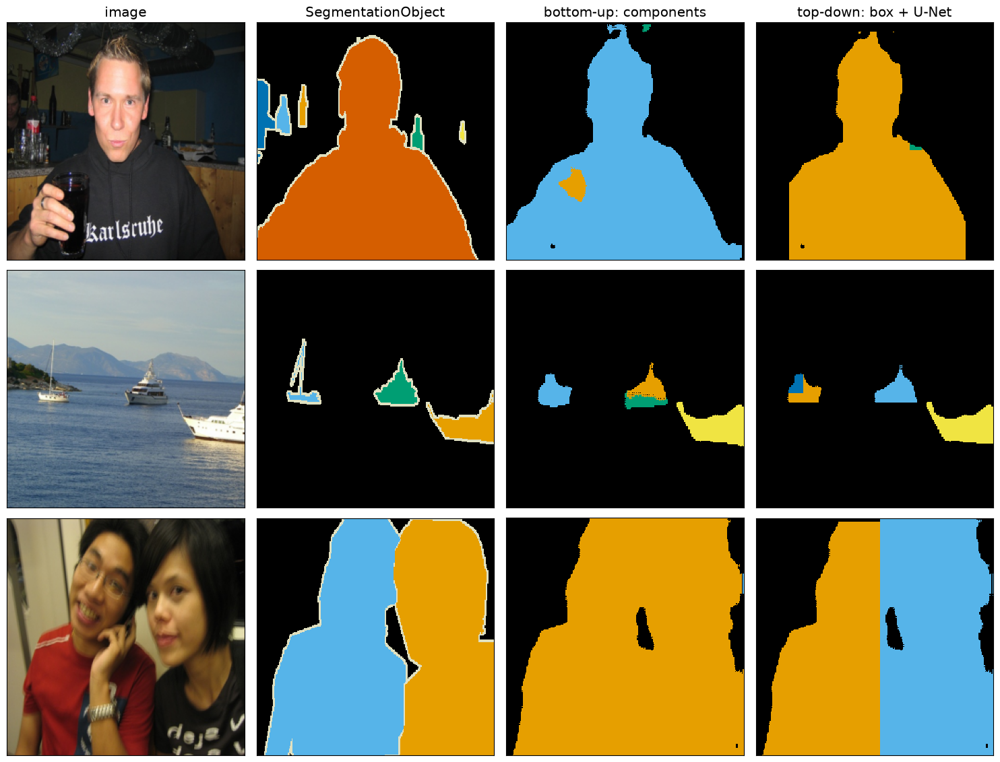

In [96]:
fig, axes = plt.subplots(3, 4, figsize=(15, 11.5))
for row, n in enumerate(SHOW):
    axes[row, 0].imshow(val_images[n].permute(1, 2, 0))
    axes[row, 1].imshow(val_instances[n], cmap=INSTANCE_CMAP, vmin=0, vmax=255, interpolation='nearest')
    for col, name in enumerate(instance_preds, start=2):
        axes[row, col].imshow(instance_map(instance_preds[name][n][0]), cmap=INSTANCE_CMAP, vmin=0, vmax=255,
                              interpolation='nearest')
for ax, title in zip(axes[0], ['image', 'SegmentationObject', *instance_preds]):
    ax.set_title(title)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

По предсказанию U-Net оба способа слабые: средний лучший IoU объекта 0.21 снизу вверх и 0.28 сверху вниз. Детектор разделяет касающихся людей (третья строка), но граница между ними — прямой край бокса: форму внутри бокса берём у U-Net, а она объекты не различает. Mask R-CNN учит маску для каждого бокса отдельно (раздел 15.3\*, раздел 17).

## 15.3\* RoIAlign и Mask R-CNN

Mask R-CNN делает «бокс + маска» одной сетью: признаки **внутри** каждого бокса → маленькая FCN-голова → маска $28 \times 28$:
$$L = L_{\text{cls}} + L_{\text{box}} + L_{\text{mask}}, \qquad L_{\text{mask}} = \mathrm{BCE}\big(\hat m_{y},\; m^{\text{GT}}\big),$$
$\hat m_y$ — маска для GT-класса бокса. Признаки фиксированного размера $m \times m$ из бокса любого размера: **RoIAlign** берёт билинейную интерполяцию карты в точках ячеек без округления координат, **RoIPool** округляет бокс до целых клеток карты.

![RoIAlign](figures/roi_align.svg)

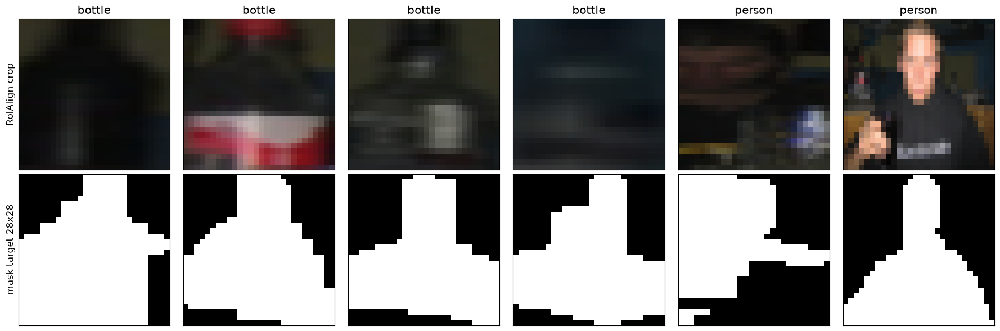

In [97]:
# таргеты маски для Mask R-CNN: GT-маска, вырезанная по своему боксу и сжатая до 28 x 28
n = 4
masks, labels = gt_instances(n)
boxes = masks_to_boxes(masks) + torch.tensor([0., 0., 1., 1.])
image = val_images[n].float() / 255
crops = roi_align(image[None], [boxes], output_size=28, aligned=True)                          # (n, 3, 28, 28)
mask_targets = roi_align(masks[:, None].float(), [b[None] for b in boxes], output_size=28, aligned=True) > 0.5

fig, axes = plt.subplots(2, len(boxes), figsize=(3 * len(boxes), 6), squeeze=False)
for k in range(len(boxes)):
    axes[0, k].imshow(crops[k].permute(1, 2, 0))
    axes[0, k].set_title(CLASSES[labels[k]])
    axes[1, k].imshow(mask_targets[k, 0], cmap='gray')
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
axes[0, 0].set_ylabel('RoIAlign crop')
axes[1, 0].set_ylabel('mask target 28x28')
plt.tight_layout()
plt.show()

In [98]:
# квантование: сдвигаем бокс по карте со stride 16 и смотрим, меняется ли выход
fmap = F.avg_pool2d(image[None], 16)   # «карта признаков» 3 x 16 x 16
box = boxes[:1]
ref_pool = roi_pool(fmap, [box], output_size=4, spatial_scale=1 / 16)
ref_align = roi_align(fmap, [box], output_size=4, spatial_scale=1 / 16, sampling_ratio=2, aligned=True)
print(f'{"shift, px":>9}{"RoIPool change":>16}{"RoIAlign change":>17}')
for dx in [2, 4, 6, 8, 10, 12, 16]:
    b = box + torch.tensor([dx, 0., dx, 0.])
    d_pool = (roi_pool(fmap, [b], output_size=4, spatial_scale=1 / 16) - ref_pool).abs().mean()
    d_align = (roi_align(fmap, [b], output_size=4, spatial_scale=1 / 16, sampling_ratio=2, aligned=True) - ref_align).abs().mean()
    print(f'{dx:>9}{d_pool:>16.4f}{d_align:>17.4f}')

shift, px  RoIPool change  RoIAlign change
        2          0.0119           0.0032
        4          0.0119           0.0055
        6          0.0119           0.0069
        8          0.0119           0.0074
       10          0.0238           0.0076
       12          0.0238           0.0087
       16          0.0238           0.0135


Маленькая бутылка и человек во весь кадр приведены к одному размеру $28 \times 28$ — так голова Mask R-CNN видит любой объект. В таблице RoIPool меняется скачками: одинаково при сдвиге бокса на 2–8 px и вдвое сильнее при 10–16 px — бокс округляется до клеток карты со stride 16. RoIAlign меняется плавно с каждым пикселем, поэтому маска не «прилипает» к сетке карты.

---
# 16. FPN детектора как основа для сегментации

Пирамида $\tilde P_3, \dots, \tilde P_6$ детектора (раздел 6) уже содержит и семантику, и разрешение. **Семантическая голова** (Panoptic FPN, Kirillov et al., 2019): каждый уровень — свёртка и upsample до $\tilde P_3$, уровни складываются, $1 \times 1$ свёртка даёт логиты, upsample — полное разрешение. Backbone и FPN берём у обученного детектора и **замораживаем**: учится только голова.

![FPN](figures/fpn.svg)

| | U-Net | FPN |
|---|---|---|
| skip | конкатенация + DoubleConv | $1 \times 1$ свёртка + сложение |
| выход | одна карта полного разрешения | пирамида с одинаковым числом каналов: голова детекции на каждом уровне, сегментация — сумма уровней |

In [99]:
class SemanticHead(nn.Module):
    def __init__(self, channels, n_classes, n_levels=4):
        super().__init__()
        self.convs = nn.ModuleList([conv_bn_relu(channels, channels) for _ in range(n_levels)])
        self.classifier = nn.Conv2d(channels, n_classes, 1)

    def forward(self, pyramid, size):
        finest = pyramid[0].shape[-2:]
        x = sum(F.interpolate(conv(p), size=finest, mode='bilinear', align_corners=False)
                for conv, p in zip(self.convs, pyramid))
        return F.interpolate(self.classifier(x), size=size, mode='bilinear', align_corners=False)


class FPNSegmenter(nn.Module):
    # backbone и FPN — у детектора раздела 6, заморожены; учится только семантическая голова
    def __init__(self, detector, channels=128):
        super().__init__()
        self.backbone, self.fpn = detector.backbone, detector.fpn
        self.backbone.requires_grad_(False)
        self.fpn.requires_grad_(False)
        self.head = SemanticHead(channels, K + 1)

    def forward(self, x):
        with torch.no_grad():
            pyramid = self.fpn(self.backbone(x))
        return self.head(pyramid, x.shape[-2:])


set_seed(0)
fpn_seg = fit_or_load('fpn_semantic_head', FPNSegmenter(detector).to(device),
                      lambda m: train_segmentation(m, seg_train_loader, SEG_EPOCHS, ce_loss), only=('head.',))

epoch 1/40: loss = 2.8308
epoch 10/40: loss = 0.5528
epoch 20/40: loss = 0.5053
epoch 30/40: loss = 0.3618
epoch 40/40: loss = 0.4208
fpn_semantic_head: loaded ./checkpoints/fpn_semantic_head.pt (training took 241 s on mps)


In [100]:
seg_results['FPN of detector + head'] = evaluate_segmentation(fpn_seg)
n_head = sum(p.numel() for p in fpn_seg.head.parameters())
print(f'trained params: U-Net {sum(p.numel() for p in unet_ce.parameters()):,}, FPN head {n_head:,}\n')
print_seg_table(seg_results)

trained params: U-Net 14,326,698, FPN head 593,557

model                      pixel acc  fg IoU   mIoU  small recall
all background                 0.738   0.000  0.035         0.000
U-Net, CE                      0.853   0.620  0.345         0.069
U-Net, no skips, CE            0.840   0.539  0.338         0.048
FPN of detector + head         0.856   0.671  0.402         0.036


Голова на замороженной пирамиде детектора — 0.59 M обучаемых параметров против 14.3 M у U-Net — сегментирует лучше: mIoU 0.402 против 0.345, fg IoU 0.671 против 0.620. Признаки детектора учились на 2501 фото с боксами, U-Net — на 209 фото с масками; боксы размечать дешевле, поэтому их обычно больше. Мелкие объекты хуже (small recall 0.036 против 0.069): самый детальный уровень пирамиды — stride 8, а у U-Net есть skip-карты со stride 2 и 4.

---
# 17. Fine-tune на своих данных: Mask R-CNN

Свои данные обычно выглядят так: папка фото и разметка из инструмента (CVAT, Label Studio) — маски PNG или JSON в формате COCO (раздел 2). Пример такого самодельного датасета — **Penn-Fudan**: уличные фото, у каждого пешехода маска. Маска — PNG, где значение пикселя — номер объекта ($0$ — фон), как `SegmentationObject` у VOC. Архив 54 МБ скачивается при первом запуске.

Чтобы взять свои фото, положите их в ту же структуру (`PNGImages/`, `PedMasks/`) или перепишите `__getitem__` под свой формат — остальной код не меняется.

In [101]:
PENN_ROOT = os.path.join(DATA_ROOT, 'PennFudanPed')
if not os.path.exists(PENN_ROOT):
    download_and_extract_archive('https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip', DATA_ROOT)
sorted(os.listdir(PENN_ROOT)), sorted(os.listdir(os.path.join(PENN_ROOT, 'PedMasks')))[:2]

(['Annotation',
  'PNGImages',
  'PedMasks',
  'added-object-list.txt',
  'readme.txt'],
 ['FudanPed00001_mask.png', 'FudanPed00002_mask.png'])

In [102]:
class PennFudan(Dataset):
    # target в формате torchvision.models.detection: boxes, labels (1 — пешеход; 0 занят фоном), masks
    def __init__(self, root, transforms=None):
        self.root, self.transforms = root, transforms
        self.names = sorted(os.listdir(os.path.join(root, 'PNGImages')))

    def __len__(self):
        return len(self.names)

    def __getitem__(self, i):
        name = self.names[i]
        image = tv_tensors.Image(read_image(os.path.join(self.root, 'PNGImages', name)))
        ids_map = read_image(os.path.join(self.root, 'PedMasks', name.replace('.png', '_mask.png')))[0]
        ids = ids_map.unique()[1:]                         # 0 — фон
        masks = ids_map[None] == ids[:, None, None]        # (n, H, W)
        boxes = masks_to_boxes(masks) + torch.tensor([0., 0., 1., 1.])   # индексы крайних пикселей -> непрерывные (раздел 1)
        target = dict(boxes=tv_tensors.BoundingBoxes(boxes, format='XYXY', canvas_size=image.shape[-2:]),
                      masks=tv_tensors.Mask(masks), labels=torch.ones(len(ids), dtype=torch.int64))
        if self.transforms is not None:
            image, target = self.transforms(image, target)
        return image, target


penn = PennFudan(PENN_ROOT)
sizes = torch.tensor([penn[i][0].shape[-2:] for i in range(len(penn))])
n_objects = sum(len(penn[i][1]['labels']) for i in range(len(penn)))
len(penn), n_objects, sizes.min(dim=0).values.tolist(), sizes.max(dim=0).values.tolist()   # (H, W) min и max

(170, 423, [311, 253], [581, 1017])

In [103]:
from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks


def show_instances(ax, image, target, title=''):
    image = image if image.dtype == torch.uint8 else (image * 255).to(torch.uint8)
    masks = target['masks'] if target['masks'].ndim == 3 else target['masks'][:, 0] > 0.5
    colors = [INSTANCE_COLORS[k % 8] for k in range(len(masks))]
    drawn = image.cpu().as_subclass(torch.Tensor)
    if len(masks):
        drawn = draw_segmentation_masks(drawn, masks.bool().cpu().as_subclass(torch.Tensor), alpha=0.5, colors=colors)
        drawn = draw_bounding_boxes(drawn, target['boxes'].cpu().as_subclass(torch.Tensor), colors=colors, width=2)
    ax.imshow(drawn.permute(1, 2, 0))
    ax.set_title(title, fontsize=11)
    ax.axis('off')

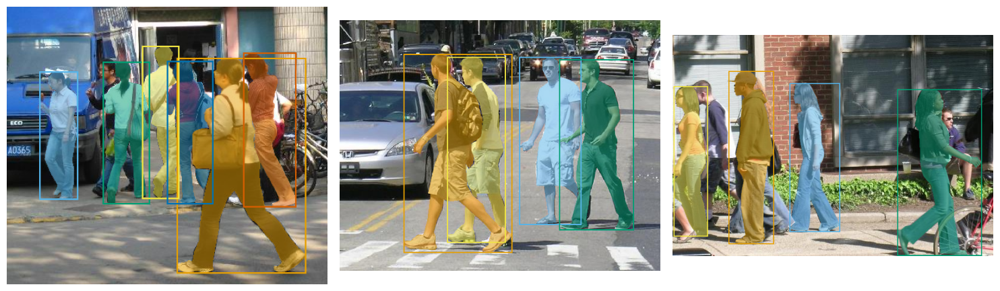

(120, 50)

In [104]:
train_tf = v2.Compose([v2.RandomHorizontalFlip(0.5), v2.RandomPhotometricDistort(p=0.5),
                       v2.ToDtype(torch.float32, scale=True)])   # те же аугментации, что в разделе 2.1
test_tf = v2.ToDtype(torch.float32, scale=True)

order = torch.randperm(len(penn), generator=torch.Generator().manual_seed(0)).tolist()
penn_train = Subset(PennFudan(PENN_ROOT, train_tf), order[:-50])
penn_test = Subset(PennFudan(PENN_ROOT, test_tf), order[-50:])

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, i in zip(axes, range(3)):
    show_instances(ax, *penn[order[i]])
plt.tight_layout()
plt.show()
len(penn_train), len(penn_test)

## 17.1 Готовая Mask R-CNN и замена голов

Detection API torchvision:
- вход — **список** картинок $(3, H, W)$ в $[0, 1]$ разного размера; resize и нормировка — внутри модели;
- `train()`: ещё список target-словарей, на выходе — словарь loss; `eval()`: список словарей `boxes`, `labels`, `scores`, `masks`.

Модель обучена на COCO (80 классов). Под свои классы заменяют две головы — классификатор боксов и предсказатель масок, — а остальное замораживают.

In [105]:
from torchvision.models.detection import MaskRCNN_ResNet50_FPN_V2_Weights, maskrcnn_resnet50_fpn_v2

weights = MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT
COCO_NAMES = weights.meta['categories']
# min_size — к чему масштабируется меньшая сторона картинки; 200 кандидатов RPN на инференсе вместо 1000:
# людей на фото единицы, а box- и mask-головы считаются на каждого кандидата
MASKRCNN_KW = dict(weights=weights, progress=False, min_size=512, max_size=864, rpn_post_nms_top_n_test=200)
coco_model = maskrcnn_resnet50_fpn_v2(**MASKRCNN_KW).to(device).eval()   # веса ~180 МБ скачиваются при первом запуске

image, target = penn_test[0]
with torch.no_grad():
    out = coco_model([image.to(device)])[0]
keep = out['scores'] > 0.5
[(COCO_NAMES[l], round(s, 3)) for l, s in zip(out['labels'][keep].tolist(), out['scores'][keep].tolist())]

[('person', 0.999),
 ('person', 0.998),
 ('person', 0.998),
 ('person', 0.997),
 ('handbag', 0.987),
 ('person', 0.975),
 ('person', 0.971),
 ('person', 0.884),
 ('person', 0.823),
 ('person', 0.791),
 ('person', 0.759),
 ('person', 0.619),
 ('skateboard', 0.597),
 ('skateboard', 0.549),
 ('person', 0.511)]

In [106]:
# внутри: FPN и anchors по уровням (разделы 5, 6), RoIAlign (раздел 15.3)
images_t, _ = coco_model.transform([image.to(device)])
with torch.no_grad():
    coco_pyramid = coco_model.backbone(images_t.tensors)
print('input after transform:', tuple(images_t.tensors.shape))
for name, p in coco_pyramid.items():
    print(f'FPN level {name:<5} {tuple(p.shape)}')
print('anchor sizes per level:', coco_model.rpn.anchor_generator.sizes)
print('RoIAlign: boxes', coco_model.roi_heads.box_roi_pool.output_size, '| masks', coco_model.roi_heads.mask_roi_pool.output_size)

input after transform: (1, 3, 512, 704)
FPN level 0     (1, 256, 128, 176)
FPN level 1     (1, 256, 64, 88)
FPN level 2     (1, 256, 32, 44)
FPN level 3     (1, 256, 16, 22)
FPN level pool  (1, 256, 8, 11)
anchor sizes per level: ((32,), (64,), (128,), (256,), (512,))
RoIAlign: boxes (7, 7) | masks (14, 14)


In [107]:
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

HEADS = ('roi_heads.box_predictor', 'roi_heads.mask_predictor')


def pedestrian_maskrcnn():
    model = maskrcnn_resnet50_fpn_v2(**MASKRCNN_KW)
    model.requires_grad_(False)                                       # готовые веса не учим
    box_in = model.roi_heads.box_predictor.cls_score.in_features
    mask_in = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.box_predictor = FastRCNNPredictor(box_in, 2)      # фон + пешеход
    model.roi_heads.mask_predictor = MaskRCNNPredictor(mask_in, 256, 2)
    return model


model = pedestrian_maskrcnn()
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
f'trainable {n_trainable:,} of {sum(p.numel() for p in model.parameters()):,} params'

'trainable 273,164 of 45,880,411 params'

In [108]:
def collate_lists(batch):
    return tuple(zip(*batch))   # картинки разного размера — списки, а не один тензор


def train_heads(model, loader, epochs, lr=0.01):
    optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=lr, momentum=0.9, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(loader))
    log = []
    for epoch in range(epochs):
        model.train()
        model.apply(lambda m: m.eval() if isinstance(m, nn.BatchNorm2d) else None)   # статистики BN замороженных слоёв не трогаем
        totals = {}
        for images, targets in loader:
            images = [img.to(device) for img in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
            losses = model(images, targets)   # loss_classifier, loss_box_reg, loss_mask, loss_objectness, loss_rpn_box_reg
            optimizer.zero_grad()
            sum(losses.values()).backward()
            optimizer.step()
            scheduler.step()
            for k, v in losses.items():
                totals[k] = totals.get(k, 0.0) + v.item() / len(loader)
        log.append(f'epoch {epoch + 1}/{epochs}: ' + ', '.join(f'{k[5:]} = {v:.3f}' for k, v in totals.items()))
    return log

In [109]:
penn_loader = DataLoader(penn_train, batch_size=2, shuffle=True, collate_fn=collate_lists,
                         generator=torch.Generator().manual_seed(0))
set_seed(0)
penn_model = fit_or_load('maskrcnn_pennfudan_heads', pedestrian_maskrcnn().to(device),
                         lambda m: train_heads(m, penn_loader, PENN_EPOCHS), only=HEADS)

epoch 1/6: classifier = 0.093, box_reg = 0.124, mask = 0.220, objectness = 0.061, rpn_box_reg = 0.002
epoch 2/6: classifier = 0.036, box_reg = 0.047, mask = 0.147, objectness = 0.058, rpn_box_reg = 0.002
epoch 3/6: classifier = 0.032, box_reg = 0.041, mask = 0.145, objectness = 0.064, rpn_box_reg = 0.001
epoch 4/6: classifier = 0.030, box_reg = 0.038, mask = 0.141, objectness = 0.063, rpn_box_reg = 0.002
epoch 5/6: classifier = 0.032, box_reg = 0.039, mask = 0.141, objectness = 0.063, rpn_box_reg = 0.002
epoch 6/6: classifier = 0.031, box_reg = 0.039, mask = 0.140, objectness = 0.060, rpn_box_reg = 0.002
maskrcnn_pennfudan_heads: loaded ./checkpoints/maskrcnn_pennfudan_heads.pt (training took 341 s on mps)


## 17.2 Оценка и ошибки

Те же инструменты, что для VOC: AP по боксам (раздел 9), лучший IoU масок (раздел 15.2), разбор ошибок (раздел 9.1). Класс «пешеход» — $0$; у COCO-модели берём только класс person.

In [110]:
@torch.no_grad()
def predict_instances(model, dataset, label):
    model.eval()
    out = []
    for image, _ in dataset:
        p = model([image.to(device)])[0]
        keep = p['labels'] == label   # уже по убыванию score
        out.append(dict(boxes=p['boxes'][keep].cpu(), scores=p['scores'][keep].cpu(),
                        labels=torch.zeros(int(keep.sum()), dtype=torch.long), masks=p['masks'][keep, 0].cpu() > 0.5))
    return out


penn_gt = [dict(boxes=t['boxes'].as_subclass(torch.Tensor), labels=t['labels'] - 1, masks=t['masks'].as_subclass(torch.Tensor))
           for _, t in penn_test]
penn_preds = {'COCO, class person': predict_instances(coco_model, penn_test, COCO_NAMES.index('person')),
              'new heads, Penn-Fudan': predict_instances(penn_model, penn_test, 1)}

In [111]:
print(f'{"model":<24}{"AP@0.5":>8}{"AP@[.5:.95]":>13}{"mask IoU":>10}   errors at score > 0.5')
for name, preds in penn_preds.items():
    ap_penn = evaluate_map(preds, penn_gt, IOU_THRESHOLDS, n_classes=1)
    confident = [{k: v[p['scores'] > 0.5] for k, v in p.items()} for p in preds]
    mask_iou = torch.cat([best_mask_iou(p['masks'], p['labels'], g['masks'], g['labels']) for p, g in zip(confident, penn_gt)])
    counts, _ = error_breakdown(preds, penn_gt, n_classes=1, score_thr=0.5)
    print(f'{name:<24}{ap_penn[0, 0]:>8.3f}{ap_penn.mean():>13.3f}{mask_iou.mean():>10.3f}   {counts}')

model                     AP@0.5  AP@[.5:.95]  mask IoU   errors at score > 0.5
COCO, class person         0.965        0.838     0.867   {'TP': 133, 'duplicate': 2, 'wrong_class': 0, 'localization': 34, 'background': 71, 'missed': 0}
new heads, Penn-Fudan      0.959        0.832     0.879   {'TP': 133, 'duplicate': 2, 'wrong_class': 0, 'localization': 27, 'background': 23, 'missed': 0}


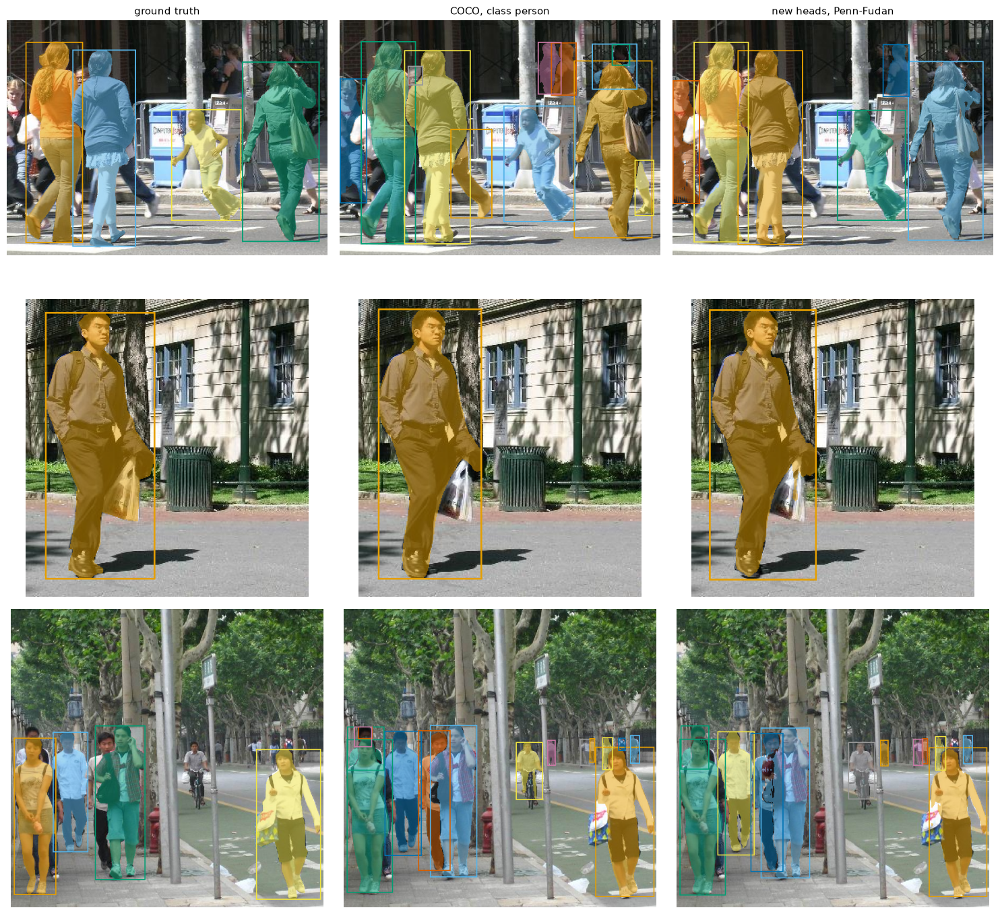

In [112]:
fig, axes = plt.subplots(3, 3, figsize=(15, 14))
for row, i in enumerate([0, 1, 2]):
    image, target = penn_test[i]
    show_instances(axes[row, 0], image, target, 'ground truth' if row == 0 else '')
    for col, (name, preds) in enumerate(penn_preds.items(), start=1):
        p = preds[i]
        show_instances(axes[row, col], image, {k: v[p['scores'] > 0.5] for k, v in p.items()}, name if row == 0 else '')
plt.tight_layout()
plt.show()

Обе модели находят всех размеченных пешеходов: класс person есть в COCO. Почти все «ложные» срабатывания — настоящие люди, которых в Penn-Fudan не разметили: дальние и обрезанные краем кадра (первая и третья строки). Новые головы выучили, кого здесь размечают: таких срабатываний втрое меньше (23 против 71 при score > 0.5), а маски точнее (IoU 0.879 против 0.867). AP при этом почти тот же (0.959 против 0.965). Со своими данными fine-tune подгоняет модель не только под классы, но и под правила разметки.

## 17.3\* YOLO: как это делают на практике

Свои данные на практике чаще всего дообучают на YOLO из библиотеки `ultralytics`: на входе — папка в формате YOLO (раздел 2) и YAML с путями и классами, обучение — один вызов `train`. Берём самую маленькую модель YOLO26n, обученную на COCO.

Внутри — одностадийный детектор, как наш (раздел 6), с двумя отличиями:
- **без anchor-боксов**: в каждой клетке карты признаков модель предсказывает расстояния от центра клетки до четырёх сторон бокса;
- **без NMS**: у головы две ветви. Ветвь «один ко многим» назначает объекту много положительных клеток, как наш matching (раздел 5), и даёт основной сигнал при обучении. Ветвь «один к одному» учится выдавать на объект одно предсказание. На инференсе работает вторая, дубликатов нет, и NMS (раздел 7) не нужен.

Лицензия `ultralytics` — AGPL-3.0: для учёбы и открытого кода свободно, для закрытого продукта нужна платная лицензия.

In [113]:
# !pip install ultralytics
from ultralytics import YOLO

YOLO_ROOT = os.path.join(DATA_ROOT, 'PennFudanYOLO')


def export_yolo(subset, split):
    # images/<split>/<имя>.png и labels/<split>/<имя>.txt: ultralytics находит разметку, заменив images на labels в пути
    for d in ('images', 'labels'):
        os.makedirs(os.path.join(YOLO_ROOT, d, split), exist_ok=True)
    for k in subset.indices:
        name = penn.names[k]
        image, target = penn[k]
        shutil.copy(os.path.join(PENN_ROOT, 'PNGImages', name), os.path.join(YOLO_ROOT, 'images', split, name))
        ann = dict(width=image.shape[-1], height=image.shape[-2],
                   boxes=target['boxes'].as_subclass(torch.Tensor), labels=target['labels'] - 1)   # пешеход — класс 0
        with open(os.path.join(YOLO_ROOT, 'labels', split, name.replace('.png', '.txt')), 'w') as f:
            f.write(to_yolo(ann))   # раздел 2


export_yolo(penn_train, 'train')
export_yolo(penn_test, 'test')
# val нужен ultralytics только для model.val(); при обучении val=False, чтобы тест не участвовал в выборе модели
yaml_text = 'train: images/train\nval: images/test\nnames:\n  0: pedestrian\n'
with open(os.path.join(YOLO_ROOT, 'penn.yaml'), 'w') as f:
    f.write(f'path: {os.path.abspath(YOLO_ROOT)}\n' + yaml_text)   # путь абсолютный: иначе ultralytics ищет в своей папке datasets
print(yaml_text)
print(open(os.path.join(YOLO_ROOT, 'labels', 'test', penn.names[penn_test.indices[0]].replace('.png', '.txt'))).read())

train: images/train
val: images/test
names:
  0: pedestrian

0 0.147280 0.519182 0.178236 0.854220
0 0.303002 0.543478 0.196998 0.836317
0 0.853659 0.558824 0.240150 0.764706
0 0.621013 0.615090 0.217636 0.473146


In [114]:
YOLO_COCO = os.path.join(CKPT_DIR, 'yolo26n.pt')   # веса COCO, ~5 МБ скачиваются при первом запуске
YOLO_CKPT = os.path.join(CKPT_DIR, 'yolo26n_pennfudan.pt')
if TRAIN or not os.path.exists(YOLO_CKPT):
    start = time.perf_counter()
    trainer_model = YOLO(YOLO_COCO)
    trainer_model.train(data=os.path.join(YOLO_ROOT, 'penn.yaml'), epochs=YOLO_EPOCHS, imgsz=640, batch=8,
                        device=str(device), val=False, plots=False, seed=0, workers=0, verbose=False,
                        project=os.path.abspath('runs'), name='yolo_pennfudan', exist_ok=True)
    shutil.copy(trainer_model.trainer.last, YOLO_CKPT)
    print(f'trained in {time.perf_counter() - start:.0f} s')
yolo_coco, yolo = YOLO(YOLO_COCO), YOLO(YOLO_CKPT)
f'YOLO26n: {sum(p.numel() for p in yolo.model.parameters()):,} params; Mask R-CNN: {sum(p.numel() for p in penn_model.parameters()):,}'

'YOLO26n: 2,533,886 params; Mask R-CNN: 45,880,411'

In [115]:
test_paths = [os.path.join(PENN_ROOT, 'PNGImages', penn.names[k]) for k in penn_test.indices]


def predict_yolo(model, paths):
    out = []
    for path in paths:
        b = model.predict(path, conf=0.05, device=str(device), verbose=False)[0].boxes.cpu()
        keep = b.cls == 0                                   # person у COCO и pedestrian у нас — оба класс 0
        order = b.conf[keep].argsort(descending=True)
        out.append(dict(boxes=b.xyxy[keep][order], scores=b.conf[keep][order], labels=torch.zeros(len(order), dtype=torch.long)))
    return out


def ms_per_image(predict, n=20):
    predict()                                               # прогрев
    start = time.perf_counter()
    for _ in range(n):
        predict()
    return 1000 * (time.perf_counter() - start) / n

In [116]:
image, _ = penn_test[0]
bgr = np.ascontiguousarray(read_image(test_paths[0]).permute(1, 2, 0).numpy()[..., ::-1])   # ultralytics ждёт numpy в BGR, как OpenCV
with torch.no_grad():
    rcnn_ms = ms_per_image(lambda: penn_model([image.to(device)])[0]['boxes'].cpu())
yolo_ms = ms_per_image(lambda: yolo.predict(bgr, device=str(device), verbose=False)[0].boxes.xyxy.cpu())

box_preds = {'Mask R-CNN, COCO person': (penn_preds['COCO, class person'], rcnn_ms),
             'Mask R-CNN, new heads': (penn_preds['new heads, Penn-Fudan'], rcnn_ms),
             'YOLO26n, COCO person': (predict_yolo(yolo_coco, test_paths), yolo_ms),
             'YOLO26n, fine-tuned': (predict_yolo(yolo, test_paths), yolo_ms)}
print(f'{"model":<25}{"ms/img":>7}{"AP@0.5":>8}{"AP@[.5:.95]":>13}   errors at score > 0.5')
for name, (preds, ms) in box_preds.items():
    ap_penn = evaluate_map(preds, penn_gt, IOU_THRESHOLDS, n_classes=1)
    counts, _ = error_breakdown(preds, penn_gt, n_classes=1, score_thr=0.5)
    print(f'{name:<25}{ms:>7.0f}{ap_penn[0, 0]:>8.3f}{ap_penn.mean():>13.3f}   {counts}')

model                     ms/img  AP@0.5  AP@[.5:.95]   errors at score > 0.5
Mask R-CNN, COCO person      453   0.965        0.838   {'TP': 133, 'duplicate': 2, 'wrong_class': 0, 'localization': 34, 'background': 71, 'missed': 0}
Mask R-CNN, new heads        453   0.959        0.832   {'TP': 133, 'duplicate': 2, 'wrong_class': 0, 'localization': 27, 'background': 23, 'missed': 0}
YOLO26n, COCO person          53   0.962        0.855   {'TP': 130, 'duplicate': 2, 'wrong_class': 0, 'localization': 12, 'background': 14, 'missed': 3}
YOLO26n, fine-tuned           53   0.956        0.787   {'TP': 120, 'duplicate': 1, 'wrong_class': 0, 'localization': 4, 'background': 4, 'missed': 13}


YOLO26n на порядок быстрее Mask R-CNN (столбец `ms/img`; на MPS время от прогона к прогону гуляет), и уже на весах COCO его боксы точнее: AP@[.5:.95] 0.855 против 0.838.

Дообучение YOLO здесь навредило: `ultralytics` по умолчанию учит все веса, и на 120 фото точность боксов упала (AP@[.5:.95] 0.787), а уверенных пропусков стало 13. Ложных срабатываний меньше (14 → 4), как и у Mask R-CNN: модель выучила, кого размечают в Penn-Fudan. На маленьком датасете замораживают тело (`train(..., freeze=10)` — первые 10 слоёв) и учат меньше эпох. А если класс уже есть в COCO, сначала проверяют готовую модель — как в первой строке таблицы.